# 07 · Robustez: de una partición estable a candidatos para piloto

Mercedes-Benz Customer Clustering — Malackathon 2026

**Objetivo:** evaluar exclusiones, escenarios de cambio y estabilidad estructural; delimitar qué asignaciones requieren revisión.


## Continuidad del estudio

Se dan por conocidos los resultados de 03 y la argumentación de las entregas anteriores. Se reutilizan sus centros, asignaciones y diagnósticos; aquí se desarrolla exclusivamente el reto indicado.

El paquete **segmentacion_ml.zip**, generado por 03 y ampliado en las siguientes entregas, contiene resultados numéricos, sin código ejecutable ni la matriz de features. Al cambiar de sesión de Colab se sube junto a los CSV. Los únicos archivos de código entregados son estos notebooks.


## Configuración

Ejecutar en orden. En Colab, usar `DATA_MODE="real_upload"`. Se excluye la clave técnica `Unnamed: 0`. La entrega 03 audita las escalas y define explícitamente una representación de varianza unitaria por variable. Las siguientes reutilizan sus parámetros, sin ajustarlos otra vez. Los CSV permanecen intactos. Cada etiqueta de cluster es local a su población.


In [1]:
from pathlib import Path
from io import BytesIO
import json, sys, importlib.util
from time import perf_counter
import uuid
STARTED = perf_counter()

# Interfaz v3: matrices de modelado y metadatos separados; resultados secuenciales.
DATA_MODE = "real"  # En Colab: "real_upload" y seleccionar los CSV y el paquete de la entrega anterior.
SEGMENT_ID = "AT_B2B"
RUN_ALL_SEGMENTS = True
SEGMENT_FILES = {name: f"{name}_features_scaled.csv" for name in ("AT_B2B", "AT_B2C", "CH_B2B", "CH_B2C")}
METADATA_FILES = {name: f"{name}_metadata.csv" for name in SEGMENT_FILES}
ID_COLUMN = "Unnamed: 0"  # Clave técnica de la exportación; nunca es una feature.
CSV_OPTIONS = dict(sep=",", decimal=".", encoding="utf-8-sig")
SCALING_POLICY = "standardize"  # Decisión explícita común: media 0 y varianza 1 por variable.
REFERENCE_FILE = "segmentacion_ml.zip"
INSTALL_MISSING = False
SEED = 42
N_INIT = 20
SILHOUETTE_SAMPLE_SIZE = 2000
FEATURE_DESCRIPTIONS = {'age_range_encoded': 'Rango de edad codificado', 'vehicle_age_years': 'Antigüedad del vehículo', 'estimated_itv_passes': 'Inspecciones técnicas estimadas', 'is_current_vehicle': 'Vehículo actual', 'months_as_mb_customer': 'Antigüedad de la relación', 'currently_connected_vehicles': 'Vehículos conectados', 'workshop_frequency_yearly': 'Frecuencia anual de taller', 'workshop_visits_warranty_goodwill': 'Visitas en garantía o atención comercial', 'marketing_receptivity_score': 'Receptividad a marketing', 'purchasing_power_per_inhabitant_eur': 'Poder adquisitivo por habitante del área', 'population': 'Población del área', 'has_telemetry_active': 'Telemetría activa', 'trip_distance_median': 'Mediana de distancia por trayecto', 'speed_median': 'Mediana de velocidad', 'fuel_consumption_average': 'Consumo medio', 'operating_hours_total': 'Horas totales de funcionamiento'}
N_RESAMPLES = 20
EXCLUSION_FRACTION = .15
SCENARIO_REPEATS = 3
GRAPH_ANCHORS = 1000
GRAPH_NEIGHBORS = 8
SCENARIOS = {"measurement_noise":(0.,.05,.15),"dominant_feature":(0.,.1,.3),"minority_attrition":(0.,.3,.6)}
NOISE_FEATURES = ("vehicle_age_years","months_as_mb_customer","workshop_frequency_yearly","fuel_consumption_average","operating_hours_total")
MIN_CLIENT_STABILITY = .8
MAX_GRID_CHANGE_FRACTION = .2
MIN_CLUSTER_JACCARD = .75
MIN_GLOBAL_ARI = .8
OUTPUT_DIR = Path("outputs") / "07" / uuid.uuid4().hex[:8]
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
required = {"numpy":"numpy>=1.26,<3", "pandas":"pandas>=2.1,<3", "sklearn":"scikit-learn>=1.3,<2",
            "scipy":"scipy>=1.11,<2", "matplotlib":"matplotlib>=3.8,<4", "threadpoolctl":"threadpoolctl>=3.2,<4"}
missing = [package for module,package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    if not INSTALL_MISSING:
        raise ImportError("Instalar las dependencias ausentes o activar INSTALL_MISSING: " + repr(missing))
    import subprocess
    subprocess.check_call([sys.executable,"-m","pip","install",*missing])
try:
    display
except NameError:
    from IPython.display import display


## Funciones del estudio

Las celdas plegadas agrupan validación, algoritmos y presentación. El desarrollo del análisis aparece después en celdas breves, cada una con su pregunta y su resultado.


In [2]:
from __future__ import annotations
"""Contrato de features procesadas y trazabilidad posicional por cliente."""


from dataclasses import dataclass
from numbers import Integral
from pathlib import Path
from typing import Iterable, Optional, Union

import numpy as np
import pandas as pd
from pandas.api.types import is_bool_dtype, is_complex_dtype, is_numeric_dtype, is_scalar


@dataclass(frozen=True)
class FeatureData:
    """Resultado validado: X[i] corresponde exactamente a client_ids.iloc[i].

    Crear mediante validate_features/load_features. X es una copia float64 de
    solo lectura; el índice original del DataFrame no se utiliza como identidad.
    Los identificadores se conservan con su tipo, sin ordenar ni convertirlos.
    """

    X: np.ndarray
    client_ids: pd.Series
    feature_names: tuple[str, ...]
    constant_features: tuple[str, ...]

    @property
    def n_samples(self) -> int:
        return self.X.shape[0]

    @property
    def n_features(self) -> int:
        return self.X.shape[1]

    def assignments(self, labels: Iterable[int]) -> pd.DataFrame:
        """Adjuntar etiquetas por posición, sin alinear índices de pandas.

        Admite etiquetas enteras (también -1 para futuras extensiones).
        Una Series debe estar ya en el orden de X; no se interpreta su índice.
        """
        values = np.asarray(list(labels))
        if values.ndim != 1 or len(values) != self.n_samples:
            raise ValueError("Debe existir una etiqueta por fila de X, en el mismo orden.")
        if values.dtype.kind not in "iu":
            raise ValueError("Las etiquetas de cluster deben ser enteros, sin nulos.")
        result = self.client_ids.reset_index(drop=True).to_frame(name="client_id").copy()
        result["cluster"] = values.copy()
        return result


def _positive_integer(value: int, name: str, minimum: int = 1) -> int:
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, Integral) or value < minimum:
        raise ValueError(f"{name} debe ser un entero >= {minimum}.")
    return int(value)


def validate_k_values(
    k_values: Iterable[int],
    n_samples: int,
    *,
    n_distinct_rows: Optional[int] = None,
) -> tuple[int, ...]:
    """Validar candidatos para clustering evaluado mediante Silhouette.

    Se exige 2 <= k < n_samples. Si se conoce la cantidad de filas distintas,
    k no puede superarla. No se modifica, ordena ni recorta la lista solicitada.
    No entrena modelos ni selecciona k. k=1 (solo codo) queda fuera del contrato
    de evaluación conjunta y podrá tratarse aparte en Fase 2.
    """
    n_samples = _positive_integer(n_samples, "n_samples", minimum=3)
    if n_distinct_rows is not None:
        n_distinct_rows = _positive_integer(n_distinct_rows, "n_distinct_rows")
        if n_distinct_rows > n_samples:
            raise ValueError("n_distinct_rows no puede superar n_samples.")
    try:
        candidates = tuple(k_values)
    except TypeError as exc:
        raise ValueError("k_values debe ser una secuencia no vacía de enteros.") from exc
    if not candidates:
        raise ValueError("k_values no puede estar vacío.")
    checked = tuple(_positive_integer(k, "k", minimum=2) for k in candidates)
    if len(set(checked)) != len(checked):
        raise ValueError("k_values contiene candidatos duplicados.")
    if any(k >= n_samples for k in checked):
        raise ValueError("Cada k debe ser menor que n_samples para evaluar Silhouette.")
    if n_distinct_rows is not None and any(k > n_distinct_rows for k in checked):
        raise ValueError("k no puede superar el número de filas de features distintas.")
    return checked


def validate_features(
    frame: pd.DataFrame,
    *,
    min_samples: int = 3,
    k_values: Optional[Iterable[int]] = None,
) -> FeatureData:
    """Validar una matriz de features sin preprocesarla.

    Acepta features reales numéricas y booleanas ya codificadas, incluidas
    extensiones numéricas nullable si no contienen nulos. Rechaza strings
    numéricos, categorías, fechas y complejos. Las columnas constantes se
    reportan y conservan; falla si ninguna feature varía.

    Complejidad O(n*p), salvo la comprobación opcional de filas únicas para k
    (ordenación, sin matrices de distancias entre clientes).
    """
    if not isinstance(frame, pd.DataFrame):
        raise TypeError("La entrada debe ser un pandas.DataFrame.")
    min_samples = _positive_integer(min_samples, "min_samples", minimum=3)
    if frame.columns.has_duplicates:
        raise ValueError("Los nombres de columnas deben ser únicos.")
    if not all(isinstance(name, str) and name.strip() for name in frame.columns):
        raise ValueError("Los nombres de columnas deben ser strings no vacíos.")
    if "client_id" not in frame.columns:
        raise ValueError("Falta la columna obligatoria client_id.")
    if len(frame) < min_samples:
        raise ValueError(f"Número insuficiente de muestras: se necesitan al menos {min_samples}.")

    ids = frame["client_id"]
    if ids.isna().any():
        raise ValueError("client_id no puede contener nulos.")
    for value in ids:
        if not is_scalar(value):
            raise ValueError("client_id debe contener identificadores escalares y hashables.")
        try:
            hash(value)
        except TypeError as exc:
            raise ValueError("client_id debe contener identificadores hashables.") from exc
        if isinstance(value, str) and not value.strip():
            raise ValueError("client_id no puede contener strings vacíos.")
        if isinstance(value, (float, np.floating)) and not np.isfinite(value):
            raise ValueError("client_id no puede contener identificadores infinitos.")
    if ids.duplicated().any():
        raise ValueError("client_id contiene identificadores duplicados.")

    names = tuple(name for name in frame.columns if name != "client_id")
    if not names:
        raise ValueError("La matriz no contiene features.")
    features = frame.loc[:, list(names)]
    incompatible = [
        name for name, dtype in features.dtypes.items()
        if not (is_numeric_dtype(dtype) or is_bool_dtype(dtype)) or is_complex_dtype(dtype)
    ]
    if incompatible:
        raise ValueError(f"Features con tipos no numéricos reales: {incompatible}.")
    if features.isna().to_numpy().any():
        raise ValueError("Las features contienen NaN o valores nulos.")
    try:
        X = features.to_numpy(dtype=np.float64, na_value=np.nan, copy=True)
    except (TypeError, ValueError, OverflowError) as exc:
        raise ValueError("Las features no pueden representarse como matriz float64.") from exc
    if not np.isfinite(X).all():
        raise ValueError("Las features contienen NaN o valores infinitos.")
    varying = np.any(X != X[0], axis=0)
    if not varying.any():
        raise ValueError("Matriz sin características útiles: todas las features son constantes.")
    if k_values is not None:
        validate_k_values(k_values, len(X), n_distinct_rows=len(np.unique(X, axis=0)))
    X = np.ascontiguousarray(X)
    X.setflags(write=False)
    return FeatureData(
        X=X,
        client_ids=ids.reset_index(drop=True).copy(deep=True),
        feature_names=names,
        constant_features=tuple(name for name, varies in zip(names, varying) if not varies),
    )


def load_features(
    source: Union[pd.DataFrame, str, Path] = "segment_01.csv",
    *,
    min_samples: int = 3,
    k_values: Optional[Iterable[int]] = None,
    csv_options: Optional[dict] = None,
) -> FeatureData:
    """Misma interfaz para DataFrame, CSV o Parquet de un segmento.

    Las rutas relativas se resuelven desde el directorio de ejecución.
    Leer Parquet requiere pyarrow; el índice guardado en el archivo no es un ID.
    """
    if isinstance(source, pd.DataFrame):
        frame = source
    elif isinstance(source, (str, Path)):
        path = Path(source)
        if path.suffix.lower() not in {".csv", ".parquet"}:
            raise ValueError("Se espera un archivo .csv o .parquet de features procesadas.")
        if not path.is_file():
            raise FileNotFoundError(f"No existe el archivo solicitado: {path}")
        try:
            frame = read_processed_table(path, csv_options=csv_options)
        except ImportError as exc:
            raise ImportError("La lectura Parquet requiere instalar pyarrow.") from exc
    else:
        raise TypeError("source debe ser un DataFrame o la ruta de un CSV/Parquet.")
    return validate_features(frame, min_samples=min_samples, k_values=k_values)


def read_processed_table(source, *, filename=None, csv_options=None, id_column="client_id"):
    """Lectura de una tabla ya procesada, sin preprocesamiento adicional.

    filename identifica el formato cuando source es un buffer de subida. Los IDs
    de CSV se conservan como texto; no se infiere su significado numérico.
    """
    suffix = str(filename if filename is not None else source).replace("\\", "/").rsplit(".", 1)[-1].lower()
    if suffix == "parquet":
        return pd.read_parquet(source, engine="pyarrow")
    if suffix != "csv":
        raise ValueError("Se espera un archivo .csv o .parquet de features procesadas.")
    options = {"sep": ",", "decimal": ".", "encoding": "utf-8-sig"}
    if csv_options:
        if set(csv_options)-set(options):
            raise ValueError("CSV_OPTIONS solo admite sep, decimal y encoding.")
        options.update(csv_options)
    return pd.read_csv(source, converters={id_column: str}, low_memory=False, **options)


In [3]:
from __future__ import annotations
"""Evaluación geométrica: muestra común y Silhouette individual por bloques."""


import numpy as np
import pandas as pd
from sklearn import config_context
from sklearn.metrics import (
    adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
    normalized_mutual_info_score, pairwise_distances_chunked, silhouette_samples,
)


def evaluation_indices(n_samples, sample_size=2000, random_state=42):
    """Muestreo uniforme sin reemplazo, independiente de las etiquetas."""
    if n_samples < 3 or not isinstance(sample_size, (int, np.integer)) or sample_size < 3:
        raise ValueError("Se necesitan n_samples y sample_size >= 3.")
    return np.sort(np.random.default_rng(random_state).choice(
        n_samples, min(n_samples, sample_size), replace=False,
    ))


def partition_scores(X, labels, *, indices=None, sample_size=2000, random_state=42):
    """DB/CH/WCSS en X completa; Silhouette en una muestra común controlada.

    WCSS se calcula respecto a las medias empíricas de la partición para poder
    comparar asignaciones de distintos algoritmos. Solo coincide con la inercia
    de K-Means cuando sus centros son esas medias. No usa etiquetas verdaderas.
    """
    labels = np.asarray(labels)
    if labels.ndim != 1 or len(labels) != len(X):
        raise ValueError("Las etiquetas deben corresponder a las filas de X.")
    if indices is None:
        indices = evaluation_indices(len(X), sample_size, random_state)
    indices = np.asarray(indices, dtype=int)
    if len(indices) < 3 or len(np.unique(indices)) != len(indices) or np.any(indices < 0) or np.any(indices >= len(X)):
        raise ValueError("Índices de evaluación inválidos.")
    unique, counts = np.unique(labels, return_counts=True)
    means = np.array([X[labels == c].mean(axis=0) for c in unique])
    wcss = sum(float(np.sum((X[labels == c] - mean) ** 2)) for c, mean in zip(unique, means))
    result = dict(
        n_clusters=len(unique), min_cluster_size=int(counts.min()),
        min_cluster_fraction=float(counts.min() / len(X)), max_cluster_fraction=float(counts.max() / len(X)),
        within_ss=wcss, silhouette=np.nan, davies_bouldin=np.nan, calinski_harabasz=np.nan,
        silhouette_n=len(indices), silhouette_estimated=len(indices) < len(X),
        silhouette_clusters_seen=len(np.unique(labels[indices])), status="ok",
    )
    if not 2 <= len(unique) < len(X):
        result["status"] = "invalid_partition"
        return result
    result["davies_bouldin"] = float(davies_bouldin_score(X, labels))
    result["calinski_harabasz"] = float(calinski_harabasz_score(X, labels))
    sub_labels = labels[indices]
    if 2 <= len(np.unique(sub_labels)) < len(indices):
        # sklearn utiliza distancias por bloques; nunca guardamos una matriz n*n.
        with config_context(working_memory=32):
            scores = silhouette_samples(X[indices], sub_labels, metric="euclidean")
        result["silhouette"] = float(scores.mean())
    else:
        result["status"] = "silhouette_undefined_in_sample"
    return result


def individual_silhouette(X, labels, *, reference_size=2000, random_state=42, working_memory=32):
    """Silhouette y vecino por cliente, sin conservar distancias cuadráticas.

    Si n<=reference_size es exacto. En datasets grandes, cada cliente se compara
    con anclas uniformes comunes: estima distancias medias por grupo, O(n*m*p),
    memoria por bloque. Esta estimación individual NO es el score global de una
    submuestra. Una clase sin anclas produce NaN en lugar de falsa certeza.
    Los singletons reales reciben 0 como en sklearn; no son evidencia de calidad.
    """
    labels = np.asarray(labels)
    if labels.shape != (len(X),) or not 2 <= len(np.unique(labels)) < len(X):
        raise ValueError("Silhouette requiere entre 2 y n-1 grupos y etiquetas por fila.")
    refs = evaluation_indices(len(X), reference_size, random_state)
    clusters, encoded = np.unique(labels, return_inverse=True)
    counts = np.bincount(encoded, minlength=len(clusters))
    ref_groups = encoded[refs]
    ref_counts = np.bincount(ref_groups, minlength=len(clusters))
    missing_clusters = int(np.sum(ref_counts == 0))
    anchor_position = np.full(len(X), -1, dtype=int)
    anchor_position[refs] = np.arange(len(refs))
    values = np.full(len(X), np.nan)
    neighbor = np.full(len(X), np.nan)
    a_all, b_all = np.full(len(X), np.nan), np.full(len(X), np.nan)
    start = 0
    for distances in pairwise_distances_chunked(X, X[refs], metric="euclidean", working_memory=working_memory):
        stop = start + len(distances)
        own = encoded[start:stop]
        position = anchor_position[start:stop]
        rows = np.arange(len(distances))
        present = position >= 0
        distances[rows[present], position[present]] = 0.0
        mean_distance = np.column_stack([
            distances[:, ref_groups == c].sum(axis=1) / ref_counts[c]
            if ref_counts[c] else np.full(len(distances), np.nan)
            for c in range(len(clusters))
        ])
        divisor = ref_counts[own] - present.astype(int)
        own_sum = np.array([distances[i, ref_groups == c].sum() for i, c in enumerate(own)])
        a = np.divide(own_sum, divisor, out=np.full(len(rows), np.nan), where=divisor > 0)
        mean_distance[rows, own] = np.inf
        mean_distance = np.where(np.isnan(mean_distance), np.inf, mean_distance)
        best = np.argmin(mean_distance, axis=1)
        b = mean_distance[rows, best]
        # Si falta un rival no sabemos si sería el grupo medio más cercano.
        valid = np.isfinite(a) & np.isfinite(b) & (missing_clusters == 0)
        scale = np.maximum(a[valid], b[valid])
        local = np.full(len(rows), np.nan)
        local[valid] = np.divide(b[valid] - a[valid], scale, out=np.zeros(valid.sum()), where=scale > 0)
        local[counts[own] == 1] = 0.0
        values[start:stop] = local
        neighbor[start:stop] = np.where(np.isfinite(b) & (missing_clusters == 0), clusters[best], np.nan)
        a_all[start:stop], b_all[start:stop] = a, np.where(np.isfinite(b) & (missing_clusters == 0), b, np.nan)
        start = stop
    return pd.DataFrame(dict(
        silhouette=values, silhouette_neighbor=neighbor, mean_own_distance=a_all,
        mean_neighbor_distance=b_all, silhouette_estimated=len(refs) < len(X),
        silhouette_reference_n=len(refs),
        silhouette_missing_anchor_clusters=missing_clusters,
    ))


def partition_geometry(X, labels):
    """Dispersión y separación entre centroides; no supone intersecciones reales."""
    labels = np.asarray(labels)
    clusters = np.unique(labels)
    rows, centers = [], {}
    for c in clusters:
        points = X[labels == c]
        center = points.mean(axis=0)
        distances = np.linalg.norm(points - center, axis=1)
        centers[c] = center
        rows.append(dict(cluster=int(c), n_clients=len(points), fraction=len(points) / len(X),
                         mean_radius=distances.mean(), rms_radius=np.sqrt(np.mean(distances**2)),
                         radius_q95=np.quantile(distances, .95)))
    summary = pd.DataFrame(rows).set_index("cluster", drop=False)
    pairs = []
    for i, a in enumerate(clusters):
        for b in clusters[i+1:]:
            distance = float(np.linalg.norm(centers[a] - centers[b]))
            scatter = float(summary.loc[a, "mean_radius"] + summary.loc[b, "mean_radius"])
            pairs.append(dict(cluster_a=int(a), cluster_b=int(b), centroid_distance=distance,
                              scatter_over_separation=scatter / distance if distance > 0 else np.inf))
    return summary.reset_index(drop=True), pd.DataFrame(pairs)


def agreement_matrices(assignments):
    """ARI y NMI invariantes a permutaciones; cada vector usa los mismos clientes."""
    names = list(assignments)
    ari = pd.DataFrame(index=names, columns=names, dtype=float)
    nmi = ari.copy()
    if len({len(v) for v in assignments.values()}) != 1:
        raise ValueError("Las particiones deben cubrir los mismos clientes en el mismo orden.")
    for a in names:
        for b in names:
            ari.loc[a, b] = adjusted_rand_score(assignments[a], assignments[b])
            nmi.loc[a, b] = normalized_mutual_info_score(assignments[a], assignments[b])
    return ari, nmi


In [4]:
from __future__ import annotations
"""Baseline, decisión multicriterio y comparación extensible con k fijo."""


from dataclasses import dataclass
from time import perf_counter
import hashlib
import warnings

import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import adjusted_rand_score
from sklearn.mixture import GaussianMixture
from threadpoolctl import threadpool_limits



def matrix_digest(X):
    """Huella de valores/forma para rechazar una referencia entrenada en otro X."""
    values = np.ascontiguousarray(X, dtype=np.float64)
    digest = hashlib.sha256(str(values.shape).encode())
    digest.update(memoryview(values).cast("B"))
    return digest.hexdigest()


def fit_kmeans(X, k, *, random_state=42, n_init=20, max_iter=300):
    validate_k_values([k], len(X), n_distinct_rows=len(np.unique(X, axis=0)))
    model = KMeans(n_clusters=k, random_state=random_state, n_init=n_init,
                   max_iter=max_iter, algorithm="lloyd", tol=1e-4)
    with threadpool_limits(limits=1):
        model.fit(X)
    model.training_digest_ = matrix_digest(X)
    return model


@dataclass
class KMeansSearch:
    table: pd.DataFrame
    models: dict
    evaluation_rows: np.ndarray


def search_kmeans(data: FeatureData, k_values=range(2, 9), *, random_state=42,
                  n_init=20, seed_repeats=3, silhouette_sample_size=2000):
    """Codo e índices geométricos; ARI entre semillas mide sensibilidad al ajuste.

    No es Jackknife ni validación de negocio. Se guarda un modelo de referencia
    por k y la misma muestra de evaluación para todos los candidatos.
    """
    candidates = validate_k_values(k_values, data.n_samples,
                                   n_distinct_rows=len(np.unique(data.X, axis=0)))
    if not isinstance(seed_repeats, int) or seed_repeats < 1:
        raise ValueError("seed_repeats debe ser un entero >= 1.")
    indices = evaluation_indices(data.n_samples, silhouette_sample_size, random_state)
    rows, models = [], {}
    for k in candidates:
        started = perf_counter()
        model = fit_kmeans(data.X, k, random_state=random_state, n_init=n_init)
        scores = partition_scores(data.X, model.labels_, indices=indices)
        stability = []
        for offset in range(1, seed_repeats):
            other = fit_kmeans(data.X, k, random_state=random_state + offset, n_init=n_init)
            stability.append(adjusted_rand_score(model.labels_, other.labels_))
        rows.append(dict(k=k, inertia=float(model.inertia_),
                         seed_ari_mean=float(np.mean(stability)) if stability else np.nan,
                         seed_ari_min=float(np.min(stability)) if stability else np.nan,
                         seed_repeats=seed_repeats, fit_seconds=perf_counter()-started, **scores))
        models[k] = model
    return KMeansSearch(pd.DataFrame(rows).sort_values("k").reset_index(drop=True), models, indices)


def select_k(search_table, *, manual_k=None, min_cluster_fraction=0.02):
    """Propuesta revisable, no estimación de un k verdadero universal.

    Rango de inercia normalizado: distancia vertical bajo la cuerda del codo.
    Agrega rangos de Silhouette .25, DB .20, CH .20, codo .20 y ARI entre
    semillas .15. Los rangos no son tests estadísticos ni métricas independientes.
    Se excluyen particiones colapsadas; tamaños mínimos son una alerta operativa.
    """
    table = search_table.copy().sort_values("k").reset_index(drop=True)
    if not 0 <= min_cluster_fraction < 1:
        raise ValueError("min_cluster_fraction debe estar en [0,1).")
    valid = ((table["n_clusters"] == table["k"]) & table["silhouette"].notna()
             & table["davies_bouldin"].notna() & table["calinski_harabasz"].notna())
    if not valid.any():
        raise ValueError("Ninguna partición admite la evaluación conjunta requerida.")
    table["elbow_strength"] = 0.0
    if len(table) >= 3 and np.ptp(table["inertia"]) > 0:
        x = (table["k"] - table["k"].min()) / np.ptp(table["k"])
        y = (table["inertia"] - table["inertia"].min()) / np.ptp(table["inertia"])
        table["elbow_strength"] = np.maximum(0, 1 - x - y)
    weights = {"silhouette": .25, "davies_bouldin": .20, "calinski_harabasz": .20,
               "elbow_strength": .20, "seed_ari_mean": .15}
    table["selection_rank"] = 0.0
    active_weight = 0.0
    for metric, weight in weights.items():
        if table.loc[valid, metric].notna().any():
            rank = table.loc[valid, metric].rank(ascending=(metric == "davies_bouldin"), method="average", pct=True)
            # rank mayor debe significar peor para todos los criterios.
            if metric != "davies_bouldin":
                rank = table.loc[valid, metric].rank(ascending=False, method="average", pct=True)
            table.loc[valid, "selection_rank"] += weight * rank.fillna(1.0)
            active_weight += weight
    table["selection_rank"] /= active_weight
    table.loc[~valid, "selection_rank"] = np.nan
    table["size_alert"] = table["min_cluster_fraction"] < min_cluster_fraction
    admissible = valid & ~table["size_alert"]
    note = "Propuesta heurística multicriterio; revisar codo, métricas, tamaños y estabilidad."
    if not admissible.any():
        admissible = valid
        note += " ALERTA: ningún candidato cumple el tamaño mínimo configurado."
    if len(table) < 3 or table["elbow_strength"].max() < .05:
        note += " No hay un codo claro en el rango estudiado."
    if manual_k is not None:
        if manual_k not in table.loc[valid, "k"].tolist():
            raise ValueError("manual_k debe ser un candidato válido ya evaluado.")
        chosen = int(manual_k)
        note += " Se utiliza la decisión manual, que requiere justificación escrita."
    else:
        chosen = int(table.loc[admissible].sort_values(["selection_rank", "k"]).iloc[0]["k"])
    table["selected"] = table["k"] == chosen
    selected = table.loc[table["selected"]].iloc[0]
    note += (f" k={chosen}; Silhouette={selected['silhouette']:.3f}, "
             f"DB={selected['davies_bouldin']:.3f}, CH={selected['calinski_harabasz']:.1f}, "
             f"grupo mínimo={selected['min_cluster_fraction']:.1%}.")
    return chosen, table, note


def fit_gmm(X, k, *, random_state=42, covariance_type="diag", n_init=5):
    """Covarianza diagonal por defecto: menos parámetros para p desconocido."""
    validate_k_values([k], len(X), n_distinct_rows=len(np.unique(X, axis=0)))
    model = GaussianMixture(n_components=k, covariance_type=covariance_type,
                            random_state=random_state, n_init=n_init, max_iter=500,
                            reg_covar=1e-5, tol=1e-3, init_params="kmeans")
    with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X)
    model.fit_warnings_ = [str(w.message) for w in captured]
    return model


@dataclass
class AlgorithmComparison:
    table: pd.DataFrame
    models: dict
    labels: dict
    ari: pd.DataFrame
    nmi: pd.DataFrame
    evaluation_rows: np.ndarray


def compare_algorithms(data, k, *, random_state=42, kmeans_model=None,
                       silhouette_sample_size=2000, covariance_type="diag", factories=None):
    """Mismo objeto X, mismo k y mismas filas de Silhouette.

    factories permite añadir {nombre: callable(X,k,seed)->modelo ajustado}.
    El modelo debe exponer predict(X) o labels_ en el orden exacto de X.
    Un algoritmo con ruido requerirá además definir una política de evaluación.
    """
    validate_k_values([k], data.n_samples, n_distinct_rows=len(np.unique(data.X, axis=0)))
    models = {"KMeans": kmeans_model if kmeans_model is not None else fit_kmeans(data.X, k, random_state=random_state)}
    if (models["KMeans"].n_clusters != k
            or getattr(models["KMeans"], "training_digest_", None) != matrix_digest(data.X)
            or not np.array_equal(models["KMeans"].predict(data.X), models["KMeans"].labels_)):
        raise ValueError("El modelo K-Means de referencia no corresponde al k/orden solicitado.")
    builders = {"GMM": lambda X, k, seed: fit_gmm(X, k, random_state=seed, covariance_type=covariance_type)}
    if factories:
        if set(factories) & {"KMeans", "GMM"}:
            raise ValueError("Los nombres KMeans/GMM están reservados.")
        builders.update(factories)
    for name, builder in builders.items():
        models[name] = builder(data.X, k, random_state)
    indices = evaluation_indices(data.n_samples, silhouette_sample_size, random_state)
    rows, labels = [], {}
    for name, model in models.items():
        labels[name] = np.asarray(model.predict(data.X) if hasattr(model, "predict") else model.labels_)
        scores = partition_scores(data.X, labels[name], indices=indices)
        converged = bool(getattr(model, "converged_", getattr(model, "n_iter_", 0) < getattr(model, "max_iter", 1)))
        rows.append(dict(algorithm=name, requested_k=k, converged=converged,
                         inertia=float(model.inertia_) if name == "KMeans" else np.nan,
                         bic=float(model.bic(data.X)) if isinstance(model, GaussianMixture) else np.nan,
                         aic=float(model.aic(data.X)) if isinstance(model, GaussianMixture) else np.nan,
                         covariance_type=getattr(model, "covariance_type", "n/a"), **scores))
    ari, nmi = agreement_matrices(labels)
    return AlgorithmComparison(pd.DataFrame(rows), models, labels, ari, nmi, indices)


def gmm_information_curve(data, k_values, *, covariance_type="diag", random_state=42):
    """Experimento BIC/AIC independiente; NO cambia el k de comparación principal."""
    k_values = tuple(k_values)
    validate_k_values(k_values, data.n_samples, n_distinct_rows=len(np.unique(data.X, axis=0)))
    rows = []
    for k in k_values:
        model = fit_gmm(data.X, k, random_state=random_state, covariance_type=covariance_type)
        rows.append(dict(k=k, bic=model.bic(data.X), aic=model.aic(data.X),
                         converged=model.converged_, covariance_type=covariance_type))
    return pd.DataFrame(rows)


def hierarchical_benchmark(data, k, *, max_samples=3000, random_state=42,
                           linkages=("ward", "average", "complete"), silhouette_sample_size=2000):
    """Experimento secundario: todos se ajustan/evalúan en la misma submatriz.

    El límite explícito acota la memoria cuadrática del jerárquico sin construir
    distancias n×n de la población. No predice etiquetas fuera de la muestra.
    Ward usa Euclídea; average/complete contrastan reglas de enlace a k fijo.
    """
    if isinstance(max_samples, bool) or not isinstance(max_samples, int) or not 3 <= max_samples <= 5000:
        raise ValueError("max_samples debe estar entre 3 y 5000 para acotar el coste jerárquico.")
    if not linkages or len(set(linkages)) != len(linkages) or set(linkages)-{"ward","average","complete","single"}:
        raise ValueError("Reglas de enlace inválidas o duplicadas.")
    positions = evaluation_indices(data.n_samples, max_samples, random_state)
    frame = pd.DataFrame(data.X[positions], columns=data.feature_names)
    frame.insert(0, "client_id", data.client_ids.iloc[positions].to_numpy())
    subset = load_features(frame, k_values=[k])
    factories = {"Agg "+linkage: lambda X, k, seed, rule=linkage:
                 AgglomerativeClustering(n_clusters=k, metric="euclidean", linkage=rule,
                                         compute_full_tree=True).fit(X) for linkage in linkages}
    result = compare_algorithms(subset, k, random_state=random_state, factories=factories,
                                silhouette_sample_size=silhouette_sample_size)
    result.table["fit_clients"] = subset.n_samples
    return subset, positions, result


In [5]:
from __future__ import annotations
"""Fronteras geométricas, pertenencia probabilística y desacuerdo de modelos."""


import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist


def align_labels(reference, candidate):
    """Alineación óptima por coincidencias sobre los mismos clientes en orden.

    Un cluster sin correspondencia recibe un entero nuevo, evitando falsos
    aciertos. ARI no necesita esta alineación. No modificar IDs ni ordenar filas.
    """
    reference, candidate = np.asarray(reference), np.asarray(candidate)
    if reference.ndim != 1 or candidate.shape != reference.shape or not len(reference):
        raise ValueError("Las dos particiones deben corresponder a los mismos clientes.")
    if reference.dtype.kind not in "iu" or candidate.dtype.kind not in "iu":
        raise ValueError("Se requieren etiquetas enteras.")
    ref_values, r = np.unique(reference, return_inverse=True)
    pred_values, p = np.unique(candidate, return_inverse=True)
    contingency = np.zeros((len(ref_values), len(pred_values)), dtype=np.int64)
    np.add.at(contingency, (r, p), 1)
    row, col = linear_sum_assignment(-contingency)
    mapping = {int(pred_values[j]): int(ref_values[i]) for i, j in zip(row, col)}
    unused = int(ref_values.min()) - 1
    for value in pred_values:
        if int(value) not in mapping:
            mapping[int(value)] = unused
            unused -= 1
    return np.array([mapping[int(value)] for value in candidate]), mapping


def kmeans_boundaries(data, model, *, boundary_threshold=.15, radial_quantile=.95, batch_size=2048):
    """Distancia exacta a la frontera de Voronoi más cercana, en X original.

    Para asignado a y competidor b: (d_b²-d_a²)/(2*||c_b-c_a||).
    El competidor de frontera más cercana puede diferir del segundo centro
    más cercano. Se muestran ambos. Normalizar por radio RMS de a permite
    comparar escalas, sin transformar el modelo ni producir probabilidades.
    Un cliente lejano puede tener margen relativo pequeño; se marca aparte.
    """
    if boundary_threshold < 0 or not 0 < radial_quantile < 1 or batch_size < 1:
        raise ValueError("Umbrales o batch_size inválidos.")
    centers = model.cluster_centers_
    k = len(centers)
    if k < 2 or centers.shape[1] != data.n_features:
        raise ValueError("El modelo debe tener al menos 2 centros compatibles con X.")
    center_dist = cdist(centers, centers)
    if np.any(center_dist[np.triu_indices(k, 1)] <= 0):
        raise ValueError("Hay centroides coincidentes; no se pueden definir fronteras únicas.")
    labels = model.predict(data.X)
    records = []
    for start in range(0, data.n_samples, batch_size):
        X = data.X[start:start+batch_size]
        distances = model.transform(X)
        own = labels[start:start+len(X)]
        rows = np.arange(len(X))
        order = np.argsort(distances, axis=1, kind="stable")
        second = np.array([order[i][order[i] != own[i]][0] for i in rows])
        d1, d2 = distances[rows, own], distances[rows, second]
        denom = 2 * center_dist[own].copy()
        denom[rows, own] = np.inf
        clearance = (distances**2 - d1[:, None]**2) / denom
        clearance[rows, own] = np.inf
        boundary_neighbor = np.argmin(clearance, axis=1)
        for i in rows:
            records.append(dict(cluster=int(own[i]), second_centroid_cluster=int(second[i]),
                                boundary_neighbor=int(boundary_neighbor[i]), distance_to_center=float(d1[i]),
                                centroid_margin=float((d2[i]-d1[i]) / max(d2[i], np.finfo(float).eps)),
                                boundary_distance=max(0., float(clearance[i, boundary_neighbor[i]]))))
    result = pd.concat([data.client_ids.to_frame().reset_index(drop=True), pd.DataFrame(records)], axis=1)
    rms = result.groupby("cluster")["distance_to_center"].agg(lambda d: np.sqrt(np.mean(d**2)))
    radial = result.groupby("cluster")["distance_to_center"].quantile(radial_quantile)
    result["boundary_distance_scaled"] = result["boundary_distance"] / result["cluster"].map(rms).clip(lower=np.finfo(float).eps)
    result["near_boundary"] = result["boundary_distance_scaled"] <= boundary_threshold
    result["radial_outlier"] = result["distance_to_center"] > result["cluster"].map(radial)
    return result


def gmm_memberships(data, model, *, confidence_threshold=.7, gap_threshold=.2,
                     membership_threshold=.2, low_density_quantile=.05):
    """Posteriors condicionados al GMM; no son confianza comercial calibrada."""
    if (not 0 <= confidence_threshold <= 1 or not 0 <= gap_threshold <= 1
            or not 0 < membership_threshold <= 1 or not 0 < low_density_quantile < 1):
        raise ValueError("Umbrales de probabilidad/densidad inválidos.")
    probabilities = model.predict_proba(data.X)
    k = probabilities.shape[1]
    if k < 2:
        raise ValueError("Se requieren al menos 2 componentes.")
    order = np.argsort(-probabilities, axis=1, kind="stable")
    rows = np.arange(data.n_samples)
    best, second = order[:, 0], order[:, 1]
    p1, p2 = probabilities[rows, best], probabilities[rows, second]
    logs = np.zeros_like(probabilities)
    np.log(probabilities, out=logs, where=probabilities > 0)
    entropy = -(probabilities * logs).sum(axis=1) / np.log(k)
    log_density = model.score_samples(data.X)
    result = data.assignments(best)
    result["second_cluster"] = second
    result["max_probability"], result["probability_gap"] = p1, p1-p2
    result["normalized_entropy"] = np.clip(entropy, 0, 1)
    result["candidate_clusters"] = ["|".join(map(str, np.flatnonzero(p >= membership_threshold))) for p in probabilities]
    result["n_candidate_clusters"] = (probabilities >= membership_threshold).sum(axis=1)
    result["ambiguous_posterior"] = (p1 < confidence_threshold) | (p1-p2 <= gap_threshold)
    result["log_density"] = log_density
    result["low_density"] = log_density < np.quantile(log_density, low_density_quantile)
    for c in range(k):
        result[f"p_cluster_{c}"] = probabilities[:, c]
    return result


def membership_overlap(memberships, *, threshold=.2):
    """Masa posterior compartida por pares; no intersección de etiquetas duras."""
    if not 0 < threshold <= 1:
        raise ValueError("threshold debe estar en (0,1].")
    columns = [c for c in memberships if c.startswith("p_cluster_")]
    rows = []
    for i, a in enumerate(columns):
        for b in columns[i+1:]:
            pa, pb = memberships[a].to_numpy(), memberships[b].to_numpy()
            rows.append(dict(cluster_a=int(a.rsplit("_", 1)[1]), cluster_b=int(b.rsplit("_", 1)[1]),
                             mean_shared_posterior=float(np.minimum(pa, pb).mean()),
                             n_joint_candidates=int(((pa >= threshold) & (pb >= threshold)).sum()),
                             membership_threshold=threshold))
    return pd.DataFrame(rows)


def ambiguity_sensitivity(boundaries, memberships):
    """Sensibilidad de los umbrales, no optimización para obtener menos ambiguos."""
    rows = []
    for threshold in (.05, .10, .15, .25, .40):
        rows.append(dict(signal="KMeans: distancia frontera/radio RMS", threshold=threshold,
                         flagged_fraction=float((boundaries["boundary_distance_scaled"] <= threshold).mean())))
    for threshold in (.5, .6, .7, .8, .9):
        rows.append(dict(signal="GMM: probabilidad máxima inferior", threshold=threshold,
                         flagged_fraction=float((memberships["max_probability"] < threshold).mean())))
    return pd.DataFrame(rows)


In [6]:
from __future__ import annotations
"""Figuras de evaluación, perfiles y robustez de clustering."""


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def plot_k_search(table, selected_k):
    columns = [("inertia", "Inercia ↓"), ("silhouette", "Silhouette ↑"),
               ("davies_bouldin", "Davies–Bouldin ↓"), ("calinski_harabasz", "Calinski–Harabasz ↑"),
               ("seed_ari_mean", "ARI entre semillas ↑"), ("min_cluster_fraction", "Fracción del grupo menor")]
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout="constrained")
    for ax, (column, title) in zip(axes.flat, columns):
        ax.plot(table["k"], table[column], "o-", color="#186B8C")
        ax.axvline(selected_k, color="#B14D25", linestyle="--", label=f"k propuesto={selected_k}")
        ax.set(xlabel="Número de clusters k", ylabel=title, title=title, xticks=table["k"])
        ax.grid(alpha=.2)
    axes.flat[0].legend()
    fig.suptitle("Contraste de criterios para k · revisar conjuntamente", fontsize=15)
    return fig


def plot_silhouette_clients(labels, values, *, estimated=False, max_points=5000):
    labels, values = np.asarray(labels), np.asarray(values)
    valid = np.flatnonzero(np.isfinite(values))
    if len(valid) > max_points:
        valid = np.sort(np.random.default_rng(42).choice(valid, max_points, replace=False))
    clusters = np.unique(labels)
    colors = plt.get_cmap("tab20", len(clusters))
    fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
    offset = 0
    for i, c in enumerate(clusters):
        ordered = np.sort(values[valid][labels[valid] == c])
        y = np.arange(offset, offset+len(ordered))
        ax.fill_betweenx(y, 0, ordered, color=colors(i), alpha=.85)
        ax.text(-.98, offset+len(ordered)/2, f"C{c} · n={len(ordered)}", va="center", fontsize=9)
        offset += len(ordered)+8
    if len(valid):
        ax.axvline(np.mean(values[valid]), color="black", linestyle="--", label="Media de clientes mostrados")
    ax.axvline(0, color="gray", linewidth=.8)
    ax.set(xlabel="Silhouette individual", ylabel="Clientes ordenados dentro de cada cluster",
           title=f"Silhouette por cliente · {'estimado con anclas' if estimated else 'exacto por bloques'}",
           xlim=(-1, 1), yticks=[])
    ax.legend(loc="lower right")
    return fig


def plot_comparison(table):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
    for ax, column, title in zip(axes, ["silhouette", "davies_bouldin", "calinski_harabasz"],
                                ["Silhouette ↑", "Davies–Bouldin ↓", "Calinski–Harabasz ↑"]):
        ax.bar(table["algorithm"], table[column], color=["#186B8C", "#D18436", "#57A773"][:len(table)] if len(table) <= 3 else "#186B8C")
        ax.set(title=title, ylabel=title)
        ax.tick_params(axis="x", rotation=35)
        ax.grid(axis="y", alpha=.2)
    return fig


def plot_heatmap(table, title, *, vmin=None, vmax=None, cmap="viridis", integer=False):
    fig, ax = plt.subplots(figsize=(max(7, min(14, len(table.columns)*.9)), max(4, min(12, len(table)*.4+1.5))), layout="constrained")
    im = ax.imshow(table.to_numpy(dtype=float), cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ticks = [f"{value:.3g}" if isinstance(value, (float, np.floating)) else str(value) for value in table.columns]
    ax.set(xticks=range(len(table.columns)), xticklabels=ticks,
           yticks=range(len(table.index)), yticklabels=table.index, title=title)
    ax.tick_params(axis="x", rotation=30)
    if table.size <= 100:
        for i in range(len(table)):
            for j in range(len(table.columns)):
                value = table.iloc[i, j]
                ax.text(j, i, f"{value:.0f}" if integer else f"{value:.2f}", ha="center", va="center",
                        bbox=dict(facecolor="white", alpha=.65, edgecolor="none", pad=1), fontsize=9)
    fig.colorbar(im, ax=ax, shrink=.8)
    return fig


def plot_cluster_sizes(labels):
    counts = pd.Series(labels).value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
    ax.bar([str(c) for c in counts.index], counts.values, color=plt.get_cmap("tab20", len(counts))(range(len(counts))))
    ax.set(xlabel="Cluster", ylabel="Clientes", title="Distribución de clientes · asignaciones duras")
    for i, count in enumerate(counts):
        ax.text(i, count, f"{count} ({count/counts.sum():.1%})", ha="center", va="bottom")
    ax.margins(y=.15)
    return fig


def plot_pca_variance(analysis):
    table = analysis.variance
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    x = np.arange(1, len(table)+1)
    axes[0].bar(x, table["explained_ratio"], color="#186B8C")
    axes[0].set(xlabel="Componente", ylabel="Fracción de varianza", title="Varianza individual")
    axes[1].plot(x, table["cumulative_ratio"], "o-", color="#186B8C")
    axes[1].axhline(.9, color="gray", linestyle="--", label="90 % como referencia")
    axes[1].set(xlabel="Número de componentes", ylabel="Varianza acumulada", ylim=(0, 1.03),
                title="Acumulada parcial" if analysis.truncated else "Varianza acumulada")
    axes[1].legend()
    return fig


def plot_pca_clusters(analysis, labels, *, ambiguous=None, title="PCA de clusters", dimensions=2,
                      max_points=6000, random_state=42, components=None, azimuth=-55):
    names = [c for c in analysis.coordinates if c != "client_id"]
    labels = np.asarray(labels)
    clusters = np.unique(labels)
    if dimensions not in (2,3) or max_points < len(clusters):
        raise ValueError("Vista de 2/3 dimensiones y presupuesto suficiente por cluster requeridos.")
    indices = tuple(range(min(dimensions,len(names)))) if components is None else tuple(components)
    if not indices or len(set(indices)) != len(indices) or any(i < 0 or i >= len(names) for i in indices):
        raise ValueError("Componentes de proyección incompatibles.")
    if components is not None and len(indices) != dimensions:
        raise ValueError("Se requiere una componente por dimensión.")
    # Muestreo por cluster: mantiene visibles grupos minoritarios. No estima densidad.
    rng = np.random.default_rng(random_state)
    budget = max_points//len(clusters)
    chosen = (np.arange(len(labels)) if len(labels)<=max_points else
              np.sort(np.concatenate([rng.choice(np.flatnonzero(labels==c),
                min(budget,int((labels==c).sum())),replace=False) for c in clusters])))
    cmap = plt.get_cmap("tab10")
    is3d = dimensions == 3 and len(indices) >= 3
    fig = plt.figure(figsize=(10, 7), layout="constrained")
    ax = fig.add_subplot(111, projection="3d" if is3d else None)
    x = analysis.coordinates[names[indices[0]]].to_numpy()
    y = analysis.coordinates[names[indices[1]]].to_numpy() if len(indices) >= 2 else np.zeros(len(x))
    z = analysis.coordinates[names[indices[2]]].to_numpy() if is3d else None
    selected = np.zeros(len(labels),dtype=bool)
    selected[chosen] = True
    for i, c in enumerate(clusters):
        mask = (labels == c) & selected
        coords = (x[mask], y[mask], z[mask]) if is3d else (x[mask], y[mask])
        ax.scatter(*coords, color=cmap(i%10), s=12, alpha=.65,
                   label=f"C{c} · total {int((labels==c).sum()):,} · vista {mask.sum():,}")
    if ambiguous is not None:
        mask = np.asarray(ambiguous, dtype=bool) & selected
        coords = (x[mask], y[mask], z[mask]) if is3d else (x[mask], y[mask])
        ax.scatter(*coords, facecolors="none", edgecolors="black", s=75, linewidths=1.2, label="Señal de ambigüedad")
    ratio = analysis.variance["explained_ratio"].to_numpy()
    axis_label = lambda i: f"{names[i]} ({ratio[i]:.1%})"
    ax.set(xlabel=axis_label(indices[0]), ylabel=axis_label(indices[1]) if len(indices)>=2 else "Sin segunda componente · vista 1D",
           title=title+f"\n{len(chosen):,}/{len(labels):,} puntos · muestreo por cluster")
    if is3d:
        ax.set_zlabel(axis_label(indices[2]))
        ax.view_init(elev=22, azim=azimuth)
    ax.legend(loc="best", fontsize=9)
    return fig


def plot_ambiguity(boundaries, memberships, *, boundary_threshold=.15):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
    axes[0].hist(boundaries["boundary_distance_scaled"], bins=25, color="#186B8C")
    axes[0].axvline(boundary_threshold, color="black", linestyle="--", label=f"Umbral {boundary_threshold:g}")
    axes[0].set(xlabel="Distancia frontera / radio RMS", ylabel="Clientes", title="K-Means: cercanía geométrica")
    axes[0].legend()
    axes[1].hist(memberships["normalized_entropy"], bins=25, color="#D18436")
    axes[1].set(xlabel="Entropía normalizada", ylabel="Clientes", title="GMM: incertidumbre condicional")
    points = axes[2].scatter(memberships["log_density"], memberships["max_probability"],
                             c=memberships["normalized_entropy"], cmap="magma", s=18)
    axes[2].set(xlabel="Log-densidad del GMM", ylabel="Probabilidad máxima", title="Atípicos y ambigüedad son distintos")
    fig.colorbar(points, ax=axes[2], label="Entropía normalizada")
    return fig


def plot_stability(result):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
    axes[0, 0].hist(result.iterations["ari"], bins=10, color="#186B8C")
    axes[0, 0].set(xlabel="ARI frente a referencia", ylabel="Submuestras", title="Estabilidad global")
    axes[0, 1].hist(result.clients["stability"].dropna(), bins=np.linspace(0, 1, 21), color="#D18436")
    axes[0, 1].set(xlabel="Aciertos / presencias", ylabel="Clientes", title="Consistencia individual alineada")
    groups = list(result.clients.groupby("cluster"))
    axes[1, 0].boxplot([g["stability"].dropna() for _, g in groups])
    axes[1, 0].set(xticks=range(1, len(groups)+1), xticklabels=[str(c) for c, _ in groups],
                   xlabel="Cluster de referencia", ylabel="Consistencia", title="Estabilidad por segmento")
    axes[1, 1].scatter(result.clients["n_present"], result.clients["stability"], s=18, alpha=.5)
    axes[1, 1].set(xlabel="Presencias en submuestras", ylabel="Consistencia", title="Cobertura de cada cliente")
    return fig


In [7]:
from __future__ import annotations
"""Presentación y contrato de intercambio de los entregables científicos."""


from dataclasses import dataclass
from html import escape
from io import BytesIO
import json
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

import numpy as np
import pandas as pd



CONTRACT_VERSION = "1.1"


def notebook_features(mode, input_path, *, id_column="client_id", upload=None, csv_options=None):
    """Leer un segmento procesado, con identificador declarado explícitamente.

    upload es un callback (como files.upload) que devuelve {nombre: bytes}.
    Se lee exactamente el contenido subido, sin depender de su ruta en Colab.
    La validación se aplica después mediante load_features.
    """
    if mode == "real":
        frame = read_processed_table(input_path, csv_options=csv_options, id_column=id_column)
    elif mode == "real_upload":
        if upload is None:
            raise ValueError("El modo real_upload requiere una función de subida manual.")
        uploaded = upload()
        filename = str(input_path).replace("\\", "/").rsplit("/", 1)[-1]
        if filename not in uploaded:
            raise FileNotFoundError(f"Subir el archivo configurado: {filename}.")
        frame = read_processed_table(BytesIO(uploaded[filename]), filename=filename,
                                     csv_options=csv_options, id_column=id_column)
    else:
        raise ValueError("DATA_MODE debe ser real o real_upload.")
    if id_column not in frame.columns:
        raise ValueError(f"Falta la columna identificadora declarada: {id_column}.")
    if id_column != "client_id":
        if "client_id" in frame.columns:
            raise ValueError("Hay dos columnas identificadoras; declarar un esquema inequívoco.")
        frame = frame.rename(columns={id_column: "client_id"})
    return frame


def format_metric(value, *, digits=3, percent=False):
    if value is None or not np.isfinite(value):
        return "No definido"
    return f"{value:.{digits if not percent else 1}{'%' if percent else 'f'}}"


@dataclass
class ReportPanel:
    title: str
    facts: dict
    findings: list
    notice: str

    def to_html(self):
        cards = "".join(
            '<div style="background:#ffffff;color:#20313c;padding:12px 16px;border:1px solid #d9e3e8;border-radius:6px;flex:1;min-width:150px">'
            f'<div style="font-size:12px;color:#52636d">{escape(str(key))}</div>'
            f'<div style="font-size:21px;font-weight:600;color:#143c4b">{escape(str(value))}</div></div>'
            for key, value in self.facts.items()
        )
        items = "".join(f'<li style="color:#20313c">{escape(str(item))}</li>' for item in self.findings)
        return (f'<section style="font-family:Arial,sans-serif;background:#f5f8fa;color:#20313c;'
                f'color-scheme:light;padding:20px;border:1px solid #d9e3e8;border-radius:10px;line-height:1.5">'
                f'<h3 style="color:#143c4b">{escape(self.title)}</h3><p style="color:#563a16;border-left:4px solid #aa6d22;padding:8px 12px;background:#fff8eb">'
                f'{escape(self.notice)}</p><div style="display:flex;flex-wrap:wrap;gap:10px">{cards}</div>'
                f'<ul style="color:#20313c">{items}</ul></section>')

    def _repr_html_(self):
        return self.to_html()

    def __repr__(self):
        return self.to_markdown()

    def to_markdown(self):
        lines = [f"# {self.title}", "", self.notice, "", "| Indicador | Resultado |", "| --- | --- |"]
        clean = lambda value: str(value).replace("|", "\\|").replace("\n", " ")
        lines.extend(f"| {clean(key)} | {clean(value)} |" for key, value in self.facts.items())
        lines.extend(["", *[f"- {item}" for item in self.findings], ""])
        return "\n".join(lines)


LABELS = {
    "k": "k", "cluster": "Cluster", "client_id": "Cliente", "n_clients": "Clientes",
    "fraction": "Proporción", "algorithm": "Algoritmo", "inertia": "Inercia ↓",
    "silhouette": "Silhouette ↑", "davies_bouldin": "Davies–Bouldin ↓",
    "calinski_harabasz": "Calinski–Harabasz ↑", "seed_ari_mean": "ARI entre semillas ↑",
    "min_cluster_fraction": "Grupo mínimo", "selected": "Seleccionado",
    "selection_rank": "Rango agregado ↓", "mean_silhouette": "Silhouette medio",
    "boundary_fraction": "Fracción fronteriza", "near_boundary": "Cerca de frontera",
    "boundary_distance_scaled": "Distancia frontera / RMS", "radial_outlier": "Atípico radial",
    "feature": "Feature", "weight": "Peso", "component": "Componente",
    "explained_ratio": "Varianza explicada", "cumulative_ratio": "Varianza acumulada",
    "converged": "Convergencia", "status": "Estado", "bic": "BIC ↓", "aic": "AIC ↓",
    "stability": "Consistencia", "n_present": "Presencias", "n_matches": "Coincidencias",
    "mean_client_stability": "Consistencia media", "unstable_fraction": "Fracción inestable",
    "normalized_entropy": "Entropía normalizada", "max_probability": "Probabilidad máxima",
    "candidate_clusters": "Componentes candidatos", "l1_bound": "Restricción s",
    "field": "Atributo", "category": "Categoría", "count": "Clientes con atributo",
    "n_known": "Valores conocidos", "share_all": "Proporción total",
    "share_known": "Proporción entre conocidos", "unknown_fraction": "Desconocidos / total",
    "global_share": "Proporción poblacional", "difference_pp": "Diferencia (pp)",
    "business_evidence": "Composición de negocio observada", "fit_clients": "Clientes de ajuste",
    "matched": "Claves coincidentes", "missing": "Sin metadatos", "coverage": "Cobertura",
    "extra_metadata": "Claves adicionales", "observed_evidence": "Contraste de comportamiento",
    "candidate_campaign": "Hipótesis de campaña", "pilot_outcome": "Resultado del piloto",
    "descriptive_axis": "Eje descriptivo", "contrast_strength": "Contraste máximo (σ)",
    "within_ss": "WCSS en X original ↓", "fit_seconds": "Tiempo de ajuste (s)",
    "max_probability": "Posterior máximo", "n_candidate_clusters": "Componentes candidatos",
    "mean_input": "Media de entrada", "std_input": "Desviación de entrada",
    "std_model": "Desviación de modelado", "variance_share_input": "Cuota de varianza de entrada",
    "variance_share_model": "Cuota de varianza de modelado", "representation": "Representación",
    "max_feature_variance_share": "Mayor cuota de varianza por variable",
    "std_min": "Desviación mínima", "std_max": "Desviación máxima",
    "pc1": "Varianza PC1", "pc1_pc2": "Varianza PC1+PC2", "eps_quantile": "Cuantil del radio",
    "coverage": "Cobertura", "noise_fraction": "Fracción de ruido", "core_clients": "Clientes núcleo",
    "border_clients": "Clientes de borde", "min_cluster_size": "Grupo menor (clientes)",
    "assigned_silhouette": "Silhouette de asignados", "kmeans_on_assigned_silhouette": "Silhouette K-Means en mismos clientes",
    "assigned_davies_bouldin": "DB de asignados", "assigned_calinski_harabasz": "CH de asignados",
    "ari_assigned": "ARI sobre asignados", "ari_including_noise": "ARI incluyendo ruido",
    "silhouette_n": "Anclas de Silhouette",
}


def reading_table(table, *, columns=None, max_rows=12):
    """Vista para el jurado; no modifica ni redondea las exportaciones completas."""
    view = table if columns is None else table.loc[:, columns]
    view = view.head(max_rows).copy()
    if not isinstance(view.columns, pd.MultiIndex):
        view = view.rename(columns=LABELS)
    return view.round(4)


def profile_clusters(data, labels, *, top_features=3):
    """Perfilado posterior al modelo, sobre coordenadas procesadas.

    El contraste descriptivo (media_cluster-media_global)/sd_global NO vuelve
    a escalar X ni se utiliza para ajustar/seleccionar modelos. No asigna nombres
    comerciales a features sin una definición de sus transformaciones.
    """
    labels = np.asarray(labels)
    if labels.shape != (data.n_samples,) or top_features < 1:
        raise ValueError("Se requieren etiquetas por cliente y top_features positivo.")
    overall = data.X.mean(axis=0)
    scale = data.X.std(axis=0)
    rows = []
    for cluster in np.unique(labels):
        points = data.X[labels == cluster]
        mean, median = points.mean(axis=0), np.median(points, axis=0)
        contrast = np.divide(mean-overall, scale, out=np.zeros(data.n_features), where=scale > 0)
        for i, name in enumerate(data.feature_names):
            rows.append(dict(cluster=int(cluster), feature=name, n_clients=len(points),
                             mean=float(mean[i]), median=float(median[i]), global_mean=float(overall[i]),
                             standardized_mean_difference=float(contrast[i])))
    profiles = pd.DataFrame(rows)
    distinct = (profiles.assign(absolute_contrast=profiles["standardized_mean_difference"].abs())
                .loc[lambda df: df["absolute_contrast"] > 0]
                .sort_values(["cluster", "absolute_contrast", "feature"], ascending=[True, False, True])
                .groupby("cluster", sort=False).head(top_features).reset_index(drop=True))
    return profiles, distinct


def baseline_decision(provenance):
    """Representación portátil de una decisión, con identidad de datos y receta."""
    keys = ("input_sha256", "feature_names", "k_values", "chosen_k", "seed", "n_init", "seed_repeats", "selection_reason")
    result = {key: provenance[key] for key in keys}
    result["contract_version"] = CONTRACT_VERSION
    result["segment_id"] = provenance.get("segment_id")
    result["selection_evidence"] = provenance.get("selection_evidence")
    return result




def validate_baseline_decision(decision, provenance):
    """Validar también una decisión incorporada al notebook por el modo lote."""
    if not isinstance(decision, dict):
        raise ValueError("La decisión baseline debe ser un objeto JSON.")
    if decision.get("contract_version") != CONTRACT_VERSION:
        raise ValueError("Versión de contrato incompatible en la decisión incorporada.")
    for key in ("input_sha256", "feature_names", "k_values", "seed", "n_init", "seed_repeats"):
        if decision.get(key) != provenance.get(key):
            raise ValueError(f"La decisión baseline no corresponde a esta entrada/configuración: {key}.")
    if decision.get("segment_id") != provenance.get("segment_id"):
        raise ValueError("La decisión baseline pertenece a otro segmento.")
    k = decision.get("chosen_k")
    if isinstance(k, bool) or not isinstance(k, int) or k not in provenance["k_values"]:
        raise ValueError("El k de la decisión no está entre los candidatos válidos.")
    return decision


In [8]:
from __future__ import annotations
"""Intercambio de resultados numéricos entre cuadernos, sin objetos ejecutables."""

import hashlib
import json
from io import BytesIO
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist


def reference_digest(X):
    values = np.ascontiguousarray(X, dtype=np.float64)
    digest = hashlib.sha256(str(values.shape).encode())
    digest.update(memoryview(values).cast("B"))
    return digest.hexdigest()


class CentroidReference:
    """Predicción de la referencia 03; esta clase no entrena un modelo nuevo."""
    def __init__(self, centers, parameters, training_digest, labels, inertia):
        self.cluster_centers_ = np.asarray(centers, dtype=float)
        self.n_clusters, self.n_features_in_ = self.cluster_centers_.shape
        self.parameters = dict(parameters)
        self.training_digest_ = training_digest
        self.labels_ = np.asarray(labels, dtype=int)
        self.inertia_ = float(inertia)

    def get_params(self, deep=True):
        return dict(self.parameters)

    def transform(self, X):
        return cdist(np.asarray(X), self.cluster_centers_)

    def predict(self, X):
        result = np.empty(len(X), dtype=int)
        for start in range(0, len(X), 8192):
            result[start:start+8192] = self.transform(X[start:start+8192]).argmin(axis=1)
        return result


def new_study():
    return {"schema_version": 2, "segments": {}}


def record_reference(study, segment_id, data, model, clients, selection):
    if not np.array_equal(model.predict(data.X), clients["cluster"].to_numpy()):
        raise ValueError("Las asignaciones no corresponden al modelo de referencia.")
    arrays = {"client_id": data.client_ids.to_numpy(dtype=str)}
    for name in clients.columns:
        if name != "client_id":
            values = clients[name].to_numpy()
            if values.dtype.kind not in "biuf":
                raise ValueError(f"Diagnóstico no numérico: {name}")
            arrays[name] = values
    study["segments"][segment_id] = {
        "feature_names": list(data.feature_names), "n_samples": data.n_samples,
        "matrix_digest": reference_digest(data.X), "centers": model.cluster_centers_.tolist(),
        "parameters": model.get_params(), "inertia": float(model.inertia_),
        "n_iter": int(model.n_iter_),
        "selection": json.loads(selection.to_json(orient="records", double_precision=15)),
        "steps": ["03"], "arrays": arrays,
    }


def save_study(study, path):
    """ZIP con JSON y NPZ sin pickle; no almacena la matriz de features."""
    manifest = {"schema_version": 2, "segments": {}}
    with ZipFile(path, "w", compression=ZIP_DEFLATED) as archive:
        for number, (identity, segment) in enumerate(study["segments"].items()):
            member = f"segment_{number}.npz"
            buffer = BytesIO()
            np.savez_compressed(buffer, **segment["arrays"])
            payload = buffer.getvalue()
            archive.writestr(member, payload)
            manifest["segments"][identity] = {key: value for key, value in segment.items() if key != "arrays"}
            manifest["segments"][identity].update(array_member=member,
                array_sha256=hashlib.sha256(payload).hexdigest())
        archive.writestr("manifest.json", json.dumps(manifest, ensure_ascii=False, allow_nan=False))
    return Path(path) if isinstance(path,(str,Path)) else path


def load_study(source):
    with ZipFile(source) as archive:
        if archive.getinfo("manifest.json").file_size > 5_000_000:
            raise ValueError("Manifest de tamaño inesperado.")
        study = json.loads(archive.read("manifest.json"))
        if study.get("schema_version") != 2 or not study.get("segments"):
            raise ValueError("Se necesita el paquete generado por el cuaderno 03.")
        for segment in study["segments"].values():
            member = segment.pop("array_member")
            if archive.getinfo(member).file_size > 200_000_000:
                raise ValueError("El bloque numérico excede el límite de lectura.")
            payload = archive.read(member)
            if hashlib.sha256(payload).hexdigest() != segment.pop("array_sha256"):
                raise ValueError("El paquete tiene un bloque numérico modificado.")
            with np.load(BytesIO(payload), allow_pickle=False) as arrays:
                segment["arrays"] = {key: arrays[key].copy() for key in arrays.files}
    return study


def restore_reference(study, segment_id, data):
    if segment_id not in study["segments"]:
        raise ValueError(f"Falta la referencia 03 de {segment_id}.")
    entry = study["segments"][segment_id]
    if entry["feature_names"] != list(data.feature_names) or entry["matrix_digest"] != reference_digest(data.X):
        raise ValueError("El CSV no coincide con la representación entrenada en 03.")
    arrays = entry["arrays"]
    if not np.array_equal(arrays["client_id"], data.client_ids.to_numpy(dtype=str)):
        raise ValueError("Los identificadores u orden no coinciden con 03.")
    if any(len(value) != data.n_samples for value in arrays.values()):
        raise ValueError("El paquete contiene diagnósticos de longitud incompatible.")
    model = CentroidReference(entry["centers"], entry["parameters"], entry["matrix_digest"],
                              arrays["cluster"], entry["inertia"])
    model.n_iter_ = entry["n_iter"]
    model.max_iter = entry["parameters"]["max_iter"]
    model.converged_ = model.n_iter_ < model.max_iter
    if not np.array_equal(model.predict(data.X), arrays["cluster"]):
        raise ValueError("Los centros no reproducen las asignaciones de 03.")
    clients = pd.DataFrame({key: values for key, values in arrays.items() if not key.startswith(("gmm_", "risk_"))})
    return model, clients, entry


In [9]:
from __future__ import annotations
"""Eliminación aleatoria repetida: estabilidad condicional a k y features fijos."""


from dataclasses import dataclass

import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score



@dataclass
class JackknifeResult:
    iterations: pd.DataFrame
    clients: pd.DataFrame
    clusters: pd.DataFrame
    transitions: pd.DataFrame
    memberships: pd.DataFrame


def jackknife_kmeans(data, k, *, reference_model=None, n_resamples=20,
                     exclusion_fraction=.15, random_state=42, vary_model_seed=False,
                     n_init=20, instability_threshold=.8, store_memberships=False):
    """20 delete-d submuestras por defecto; no es inferencia jackknife clásica.

    Sin reemplazo dentro de cada submuestra. ARI referencia/submuestra y
    alineación húngara usan SOLO las posiciones/IDs presentes. Consistencia
    individual = coincidencias/presencias, no coincidencias/n_resamples.
    Las submuestras se solapan; no se producen intervalos de confianza ingenuos.
    La alineación maximiza coincidencias y puede ser optimista: ARI es primaria.
    """
    if not isinstance(n_resamples, int) or isinstance(n_resamples, bool) or n_resamples < 2:
        raise ValueError("n_resamples debe ser un entero >= 2.")
    if not 0 < exclusion_fraction < 1 or not 0 <= instability_threshold <= 1:
        raise ValueError("Fracción de exclusión o umbral de estabilidad inválidos.")
    n_keep = int(np.floor(data.n_samples * (1-exclusion_fraction)))
    validate_k_values([k], n_keep)
    reference_model = reference_model if reference_model is not None else fit_kmeans(data.X, k, random_state=random_state, n_init=n_init)
    if reference_model.n_clusters != k or getattr(reference_model, "training_digest_", None) != matrix_digest(data.X):
        raise ValueError("La referencia no corresponde a la matriz X y al k solicitados.")
    reference = reference_model.predict(data.X)
    if len(np.unique(reference)) != k:
        raise ValueError("La referencia tiene clusters colapsados.")
    rng = np.random.default_rng(random_state)
    present = np.zeros(data.n_samples, dtype=int)
    matches = np.zeros(data.n_samples, dtype=int)
    votes = np.zeros((data.n_samples, k+1), dtype=int)  # Última columna: sin correspondencia.
    transitions = np.zeros((k, k+1), dtype=int)
    rows, membership_rows = [], []
    for iteration in range(n_resamples):
        positions = np.sort(rng.choice(data.n_samples, n_keep, replace=False))
        model_seed = random_state + iteration + 1 if vary_model_seed else random_state
        model = fit_kmeans(data.X[positions], k, random_state=model_seed, n_init=n_init)
        labels = model.predict(data.X[positions])
        ref = reference[positions]
        aligned, _ = align_labels(ref, labels)
        equal = aligned == ref
        present[positions] += 1
        matches[positions] += equal.astype(int)
        # Puede faltar un segmento de referencia en la submuestra. Un nuevo
        # grupo sin pareja no se fuerza a coincidir con otro: cuenta como cambio.
        bucket = np.where(aligned < 0, k, aligned)
        np.add.at(votes, (positions, bucket), 1)
        np.add.at(transitions, (ref, bucket), 1)
        rows.append(dict(iteration=iteration, model_seed=model_seed, n_present=n_keep,
                         exclusion_fraction_actual=1-n_keep/data.n_samples,
                         ari=float(adjusted_rand_score(ref, labels)), aligned_agreement=float(equal.mean()),
                         observed_clusters=len(np.unique(labels)), reference_clusters_present=len(np.unique(ref)),
                         unmatched_fraction=float((aligned < 0).mean())))
        if store_memberships:
            membership_rows.append(pd.DataFrame({
                "iteration": iteration, "client_id": data.client_ids.iloc[positions].to_numpy(),
                "reference_cluster": ref, "aligned_cluster": aligned, "match": equal,
            }))
    stability = np.divide(matches, present, out=np.full(data.n_samples, np.nan), where=present > 0)
    clients = data.assignments(reference)
    clients["n_present"], clients["n_matches"], clients["stability"] = present, matches, stability
    clients["insufficient_presence"] = present < max(3, int(np.floor(n_resamples*.5)))
    clients["unstable"] = (stability < instability_threshold) & (present > 0)
    for c in range(k):
        clients[f"aligned_fraction_{c}"] = np.divide(votes[:, c], present, out=np.full(data.n_samples, np.nan), where=present > 0)
    clients["unmatched_fraction"] = np.divide(votes[:, k], present, out=np.full(data.n_samples, np.nan), where=present > 0)
    groups = []
    for c, group in clients.groupby("cluster"):
        seen = group["n_present"] > 0
        total = int(group["n_present"].sum())
        groups.append(dict(cluster=c, n_clients=len(group), n_unseen=int((~seen).sum()),
                           mean_client_stability=group.loc[seen, "stability"].mean(),
                           pooled_agreement=float(group["n_matches"].sum()/total) if total else np.nan,
                           unstable_fraction=float(group.loc[seen, "unstable"].mean()) if seen.any() else np.nan,
                           total_presences=total))
    return JackknifeResult(pd.DataFrame(rows), clients, pd.DataFrame(groups),
                           pd.DataFrame(transitions, index=range(k), columns=[*range(k), "unmatched"]),
                           pd.concat(membership_rows, ignore_index=True) if membership_rows else pd.DataFrame(
                               columns=["iteration", "client_id", "reference_cluster", "aligned_cluster", "match"]))


In [10]:
from __future__ import annotations
"""Estrés de datos y grafos de vecindad, condicional a k y representación."""

from dataclasses import dataclass

import numpy as np
import pandas as pd
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from threadpoolctl import threadpool_limits



def _edge_distances(X, neighbors):
    count = min(neighbors, len(X)-1)
    if count < 1:
        return {}
    with threadpool_limits(limits=1):
        model = NearestNeighbors(n_neighbors=count, metric="euclidean", n_jobs=1).fit(X)
        distances, indices = model.kneighbors()
    edges = {}
    for row, (targets, lengths) in enumerate(zip(indices, distances)):
        for target, length in zip(targets, lengths):
            pair = (min(row, int(target)), max(row, int(target)))
            edges[pair] = min(edges.get(pair, np.inf), float(length))
    return edges


def _jaccard(left, right):
    union = left | right
    return len(left & right)/len(union) if union else 1.


def _components(n, edges):
    if not edges:
        return n, 1/n if n else np.nan
    row, col = zip(*edges)
    graph = coo_matrix((np.ones(len(row)), (row, col)), shape=(n, n)).tocsr()
    count, labels = connected_components(graph, directed=False)
    return int(count), float(np.bincount(labels).max()/n)


def neighborhood_stability(original, altered, reference_labels, aligned_labels, *, neighbors=8,
                           distance_quantiles=(.5, .75, .9)):
    """Grafo k-NN disperso sobre las MISMAS filas en ambas representaciones.

    Radios fijados con distancias de referencia, nunca recalibrados tras alterar.
    No calcula homología persistente ni estima la topología de toda la población.
    Los empates pueden cambiar aristas k-NN; se informa duplicación y distancia cero.
    """
    original, altered = np.asarray(original), np.asarray(altered)
    if original.shape != altered.shape or original.ndim != 2 or len(original) < 3:
        raise ValueError("Se necesitan al menos tres anclas comunes de forma compatible.")
    if neighbors < 1 or any(not 0 <= q <= 1 for q in distance_quantiles):
        raise ValueError("Vecinos o cuantiles de distancia inválidos.")
    if len(reference_labels) != len(original) or len(aligned_labels) != len(original):
        raise ValueError("Las etiquetas deben corresponder a las anclas comunes.")
    before, after = _edge_distances(original, neighbors), _edge_distances(altered, neighbors)
    lengths = np.array(list(before.values()))
    pairs_before = {(min(int(reference_labels[a]), int(reference_labels[b])), max(int(reference_labels[a]), int(reference_labels[b])))
                    for a, b in before if reference_labels[a] != reference_labels[b]}
    pairs_after = {(min(int(aligned_labels[a]), int(aligned_labels[b])), max(int(aligned_labels[a]), int(aligned_labels[b])))
                   for a, b in after if aligned_labels[a] != aligned_labels[b]}
    summary = dict(neighbor_edge_jaccard=_jaccard(set(before), set(after)),
                   segment_adjacency_jaccard=_jaccard(pairs_before, pairs_after),
                   reference_segment_edges=len(pairs_before), altered_segment_edges=len(pairs_after),
                   duplicate_anchor_fraction=1-len(np.unique(original, axis=0))/len(original),
                   zero_distance_edge_fraction=float((lengths == 0).mean()), graph_anchor_n=len(original),
                   graph_reference_clusters_seen=len(np.unique(reference_labels)),
                   graph_altered_clusters_seen=len(np.unique(aligned_labels)))
    scales = []
    for quantile in distance_quantiles:
        radius = float(np.quantile(lengths, quantile))
        left = {pair for pair, distance in before.items() if distance <= radius}
        right = {pair for pair, distance in after.items() if distance <= radius}
        original_count, original_largest = _components(len(original), left)
        altered_count, altered_largest = _components(len(original), right)
        scales.append(dict(distance_quantile=quantile, reference_radius=radius,
            radius_edge_jaccard=_jaccard(left, right), reference_components=original_count,
            altered_components=altered_count, reference_largest_fraction=original_largest,
            altered_largest_fraction=altered_largest))
    return summary, pd.DataFrame(scales)


def perturb_rows(data, reference_labels, family, severity, *, seed, noise_features, dominant_feature=None):
    """Escenarios analíticos en coordenadas procesadas, no predicción de sucesos."""
    if not np.isfinite(severity) or not 0 <= severity < 1:
        raise ValueError("La intensidad debe estar en [0,1).")
    rng = np.random.default_rng(seed)
    positions = np.arange(data.n_samples)
    X = data.X.copy()
    detail = "control"
    if family == "measurement_noise":
        unknown = set(noise_features)-set(data.feature_names)
        if unknown:
            raise ValueError(f"Features de ruido desconocidas: {sorted(unknown)}")
        columns = [data.feature_names.index(name) for name in noise_features]
        if not columns:
            raise ValueError("Declarar las variables continuas para el escenario de ruido.")
        values = X[:, columns]
        q25, q75 = np.quantile(values, [.25, .75], axis=0)
        scale = (q75-q25)/1.349
        scale = np.where(scale > 0, scale, values.std(axis=0))
        X[:, columns] += severity*scale*rng.normal(size=values.shape)
        detail = " | ".join(noise_features)
    elif family == "dominant_feature":
        column = (int(data.X.var(axis=0).argmax()) if dominant_feature is None
                  else data.feature_names.index(dominant_feature))
        median = np.median(X[:, column])
        X[:, column] = median+(1-severity)*(X[:, column]-median)
        detail = data.feature_names[column]
    elif family == "minority_attrition":
        clusters, counts = np.unique(reference_labels, return_counts=True)
        target = clusters[np.argmin(counts)]
        members = np.flatnonzero(reference_labels == target)
        removed = rng.permutation(members)[:int(np.floor(severity*len(members)))]
        positions = np.setdiff1d(positions, removed, assume_unique=True)
        X = X[positions]
        detail = f"C{target}: excluidos {len(removed)}/{len(members)}"
    else:
        raise ValueError("Familia de perturbación desconocida.")
    return positions, X, detail


def most_separating_feature(data, labels):
    """Mayor dispersión entre medias de clusters, ponderada por tamaño.

    Con varianzas unitarias, argmax de varianza total sería un empate numérico;
    este criterio identifica una dependencia de la partición, no de la escala.
    """
    labels=np.asarray(labels)
    if labels.shape != (data.n_samples,):
        raise ValueError("Se requiere una etiqueta por fila.")
    mean=data.X.mean(axis=0)
    between=np.zeros(data.n_features)
    for cluster in np.unique(labels):
        group=data.X[labels==cluster]
        between += len(group)*(group.mean(axis=0)-mean)**2
    return data.feature_names[int(between.argmax())]


@dataclass
class PerturbationStudy:
    runs: pd.DataFrame
    clusters: pd.DataFrame
    clients: pd.DataFrame
    topology_scales: pd.DataFrame


def perturbation_study(data, reference_model, *, scenarios=None, repeats=3, random_state=42,
                       noise_features=(), graph_anchors=1000, graph_neighbors=8, dominant_feature=None):
    """Mismo k/receta; distinguir clasificación vigente, reajuste y anclas intactas.

    Las fracciones por cliente describen el grid elegido, no una probabilidad.
    La exclusión cuenta solo clientes presentes. Se conserva la semilla del modelo
    para separar la alteración de datos de variación de inicialización.
    """
    if repeats < 1 or graph_anchors < 3 or graph_neighbors < 1:
        raise ValueError("Repeticiones, anclas o vecinos inválidos.")
    if getattr(reference_model, "training_digest_", None) != matrix_digest(data.X):
        raise ValueError("La referencia no corresponde a X.")
    scenarios = scenarios or {"measurement_noise": (0., .05, .15),
                              "dominant_feature": (0., .1, .3), "minority_attrition": (0., .3, .6)}
    reference = reference_model.predict(data.X)
    parameters = reference_model.get_params()
    if parameters.get("max_iter", 300) != 300 or parameters.get("tol", 1e-4) != 1e-4:
        raise ValueError("La receta de reajuste requiere max_iter=300 y tol=1e-4, como la referencia.")
    rng = np.random.default_rng(random_state)
    anchors = np.sort(rng.choice(data.n_samples, min(graph_anchors, data.n_samples), replace=False))
    clients = data.assignments(reference)
    rows, cluster_rows, scales = [], [], []
    for family_number, (family, severities) in enumerate(scenarios.items()):
        present, frozen_changes, refit_changes = (np.zeros(data.n_samples, dtype=int) for _ in range(3))
        for severity in sorted(set(severities)):
            for repetition in range(1 if severity == 0 or family == "dominant_feature" else repeats):
                seed = random_state + 1000*family_number + repetition
                positions, altered, detail = perturb_rows(data, reference, family, severity,
                    seed=seed, noise_features=noise_features,dominant_feature=dominant_feature)
                before = reference[positions]
                frozen = reference_model.predict(altered)
                model = reference_model if severity == 0 else fit_kmeans(altered, reference_model.n_clusters,
                    random_state=parameters["random_state"], n_init=parameters["n_init"], max_iter=300)
                after = model.predict(altered)
                aligned, mapping = align_labels(before, after)
                common = np.intersect1d(anchors, positions, assume_unique=True)
                if len(common) < 3:
                    raise ValueError("Menos de tres anclas presentes; ampliar graph_anchors.")
                offsets = np.searchsorted(positions, common)
                anchor_original = data.X[common]
                anchor_altered = altered[offsets]
                graph_summary, scale = neighborhood_stability(anchor_original, anchor_altered,
                    reference[common], aligned[offsets], neighbors=graph_neighbors)
                # Las mismas anclas se mantienen sin modificar para aislar el movimiento del modelo.
                anchor_predictions = model.predict(anchor_original)
                anchor_aligned = np.array([mapping.get(int(value), -1) for value in anchor_predictions])
                row = dict(family=family, severity=float(severity), repetition=repetition,
                    perturbation_seed=seed, model_seed=parameters["random_state"], detail=detail,
                    n_present=len(positions), removed_fraction=1-len(positions)/data.n_samples,
                    frozen_ari=float(adjusted_rand_score(before, frozen)),
                    refit_ari=float(adjusted_rand_score(before, after)),
                    frozen_changed_fraction=float((frozen != before).mean()),
                    refit_changed_fraction=float((aligned != before).mean()),
                    untouched_anchor_ari=float(adjusted_rand_score(reference[common], anchor_predictions)),
                    untouched_anchor_changed_fraction=float((anchor_aligned != reference[common]).mean()),
                    refit_converged=bool(model.n_iter_ < model.max_iter),
                    refit_observed_clusters=len(np.unique(after)), reference_clusters_present=len(np.unique(before)),
                    **graph_summary)
                rows.append(row)
                scale = scale.assign(family=family, severity=float(severity), repetition=repetition)
                scales.append(scale)
                for cluster in range(reference_model.n_clusters):
                    left, right = before == cluster, aligned == cluster
                    union, intersection = int((left | right).sum()), int((left & right).sum())
                    cluster_rows.append(dict(family=family, severity=float(severity), repetition=repetition,
                        cluster=cluster, n_reference_present=int(left.sum()),
                        membership_jaccard=intersection/union if left.any() and union else np.nan,
                        retained_fraction=intersection/left.sum() if left.any() else np.nan))
                if severity > 0:
                    present[positions] += 1
                    frozen_changes[positions] += frozen != before
                    refit_changes[positions] += aligned != before
        clients[family+"_n_present"] = present
        clients[family+"_frozen_change_fraction"] = np.divide(frozen_changes, present,
            out=np.full(data.n_samples, np.nan), where=present > 0)
        clients[family+"_refit_change_fraction"] = np.divide(refit_changes, present,
            out=np.full(data.n_samples, np.nan), where=present > 0)
    return PerturbationStudy(pd.DataFrame(rows), pd.DataFrame(cluster_rows), clients, pd.concat(scales, ignore_index=True))


In [11]:
from __future__ import annotations
"""Auditoría de escalas y representación explícita compartida entre entregas."""

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler



def scale_audit(data):
    variance = data.X.var(axis=0)
    return pd.DataFrame(dict(feature=data.feature_names, mean=data.X.mean(axis=0),
        std=data.X.std(axis=0), minimum=data.X.min(axis=0), maximum=data.X.max(axis=0),
        variance_share=variance/variance.sum(), constant=variance==0))


def apply_representation(raw, specification):
    """Aplicar los parámetros de 03, sin volver a estimarlos en cada entrega."""
    if (specification["feature_names"] != list(raw.feature_names)
            or specification["raw_digest"] != reference_digest(raw.X)):
        raise ValueError("La entrada no coincide con la usada para definir la representación en 03.")
    mean = np.asarray(specification["mean"],dtype=float)
    scale = np.asarray(specification["scale"],dtype=float)
    if (mean.shape != (raw.n_features,) or scale.shape != mean.shape
            or not np.isfinite(mean).all() or not np.isfinite(scale).all() or np.any(scale<=0)):
        raise ValueError("Parámetros de estandarización inválidos.")
    X = (raw.X-mean)/scale
    if not np.isfinite(X).all():
        raise ValueError("La representación contiene valores no finitos.")
    X.setflags(write=False)
    return FeatureData(X,raw.client_ids.copy(),raw.feature_names,raw.constant_features)


def fit_representation(raw, *, policy="standardize"):
    """Varianza poblacional unitaria por variable, incluida cada variable binaria.

    Es una decisión explícita de geometría, no una limpieza del CSV. Si la
    matriz ya está centrada y tiene varianza unitaria se conserva la identidad.
    Las constantes mantienen escala 1. No normaliza cada fila a norma unitaria.
    """
    if policy not in ("standardize","as_received"):
        raise ValueError("policy debe ser standardize o as_received.")
    audit = scale_audit(raw)
    active = ~audit["constant"].to_numpy()
    already = (np.allclose(audit["mean"],0,atol=1e-8,rtol=0)
               and np.allclose(audit.loc[active,"std"],1,atol=1e-8,rtol=0))
    scaler = StandardScaler().fit(raw.X) if policy=="standardize" and not already else None
    specification = dict(policy=policy,applied=scaler is not None,
        feature_names=list(raw.feature_names),raw_digest=reference_digest(raw.X),
        mean=scaler.mean_.tolist() if scaler is not None else [0.]*raw.n_features,
        scale=scaler.scale_.tolist() if scaler is not None else [1.]*raw.n_features,
        convention="ddof=0; parámetros de la población de referencia; constantes con escala 1")
    return apply_representation(raw,specification), specification


## Lectura de las matrices

Una fila por clave técnica. Se comprueban finitud, tipos, unicidad e integridad antes del cálculo.


In [12]:
import sklearn, scipy, matplotlib
VERSIONS = dict(python=sys.version.split()[0], numpy=np.__version__, pandas=pd.__version__,
                sklearn=sklearn.__version__, scipy=scipy.__version__, matplotlib=matplotlib.__version__)
plt.rcParams.update({"font.size":11,"axes.titlesize":13,"figure.facecolor":"white",
                     "axes.facecolor":"white","axes.edgecolor":"#344854","axes.labelcolor":"#20313c",
                     "text.color":"#20313c","xtick.color":"#20313c","ytick.color":"#20313c",
                     "axes.spines.top":False,"axes.spines.right":False})
RESULT_TABLES = {}
FIGURE_COUNT = 0

def display_table(table, title, max_rows=16):
    print(title)
    display(reading_table(table, max_rows=max_rows))

def keep_table(segment, name, table):
    RESULT_TABLES[segment+" / "+name] = table

def show_figures(segment):
    global FIGURE_COUNT
    for number in plt.get_fignums():
        FIGURE_COUNT += 1
        figure = plt.figure(number)
        figure.text(.01,-.025,segment+" · Mercedes-Benz · matriz procesada",fontsize=8)
        figure._delivery_filename = f"{segment}_figure_{FIGURE_COUNT:03d}.png"
        figure._delivery_output_dir = str(OUTPUT_DIR)
    plt.show()
    plt.close("all")

def available_file(path):
    for candidate in (Path(path), Path("data/processed")/Path(path).name, Path("../data/processed")/Path(path).name):
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(f"Falta {Path(path).name}. En Colab, usar real_upload.")

uploaded = None
if DATA_MODE == "real_upload":
    from google.colab import files
    uploaded = files.upload()
elif DATA_MODE != "real":
    raise ValueError("DATA_MODE debe ser real o real_upload.")
ACTIVE_SEGMENTS = list(SEGMENT_FILES) if RUN_ALL_SEGMENTS else [SEGMENT_ID]
analyses = {}


# Validar la representación es necesario para no aplicar una referencia a otras filas.
for segment in ACTIVE_SEGMENTS:
    path = SEGMENT_FILES[segment]
    frame = notebook_features(DATA_MODE, available_file(path) if uploaded is None else path,
        id_column=ID_COLUMN, csv_options=CSV_OPTIONS, upload=lambda:uploaded)
    data = load_features(frame)
    analyses[segment] = dict(data=data,raw_data=data)
    del frame


## Recuperar la referencia de 03

Se verifican features, valores, identificadores, orden y asignaciones. Una entrada distinta exige volver a ejecutar 03; no se sustituye silenciosamente la referencia.


In [13]:
# Leer resultados numéricos de 03: no se selecciona k ni se vuelve a ajustar K-Means.
study = load_study(available_file(REFERENCE_FILE) if uploaded is None else BytesIO(uploaded[REFERENCE_FILE]))
for segment, context in analyses.items():
    specification = study["segments"][segment].get("representation")
    if specification is None or specification["policy"] != SCALING_POLICY:
        raise ValueError("Volver a ejecutar 03 con la política de escala actual y usar su paquete nuevo.")
    context["data"] = apply_representation(context["raw_data"],specification)
    context["representation"] = specification
    model, clients, entry = restore_reference(study, segment, context["data"])
    context.update(model=model, clients=clients, labels=clients["cluster"].to_numpy(), entry=entry)


## Jackknife Clustering: exclusión aleatoria repetida

Se excluye 15 % sin reemplazo en 20 iteraciones, manteniendo k, representación, n_init y semilla de ajuste de 03. ARI compara solo clientes presentes. La asignación húngara permite contar coincidencias; cada cliente usa sus presencias como denominador. Las submuestras se solapan: no se presenta inferencia jackknife clásica ni IC binomiales.


In [14]:
for segment, context in analyses.items():
    model=context["model"]
    context["jackknife"]=jackknife_kmeans(context["data"],model.n_clusters,reference_model=model,
        n_resamples=N_RESAMPLES,exclusion_fraction=EXCLUSION_FRACTION,
        random_state=model.get_params()["random_state"],n_init=model.get_params()["n_init"],
        instability_threshold=MIN_CLIENT_STABILITY,store_memberships=False)


## Estabilidad global, por grupo y por cliente

La mediana puede ocultar una partición ocasional distinta. Se conserva el mínimo de ARI y se inspeccionan grupos pequeños y clientes con cobertura insuficiente. Una alineación óptima puede favorecer coincidencias; por eso ARI acompaña la consistencia individual.


AT_B2B · consistencia por cluster


,Cluster,Clientes,n_unseen,Consistencia media,pooled_agreement,Fracción inestable,total_presences
0,0,2297,0,0.9994,0.9995,0.0004,39042
1,1,225,0,0.9886,0.9887,0.0267,3818


AT_B2B · cola de inestabilidad


,iteration,ari,aligned_agreement,reference_clusters_present,unmatched_fraction
0,0,0.9896,0.9986,2,0.0
1,1,0.9932,0.9991,2,0.0
2,2,0.9930,0.9991,2,0.0
3,3,0.9966,0.9995,2,0.0
4,4,0.9933,0.9991,2,0.0
5,5,0.9755,0.9967,2,0.0
6,6,0.9931,0.9991,2,0.0
7,7,0.9827,0.9977,2,0.0
8,8,0.9930,0.9991,2,0.0
9,9,0.9930,0.9991,2,0.0


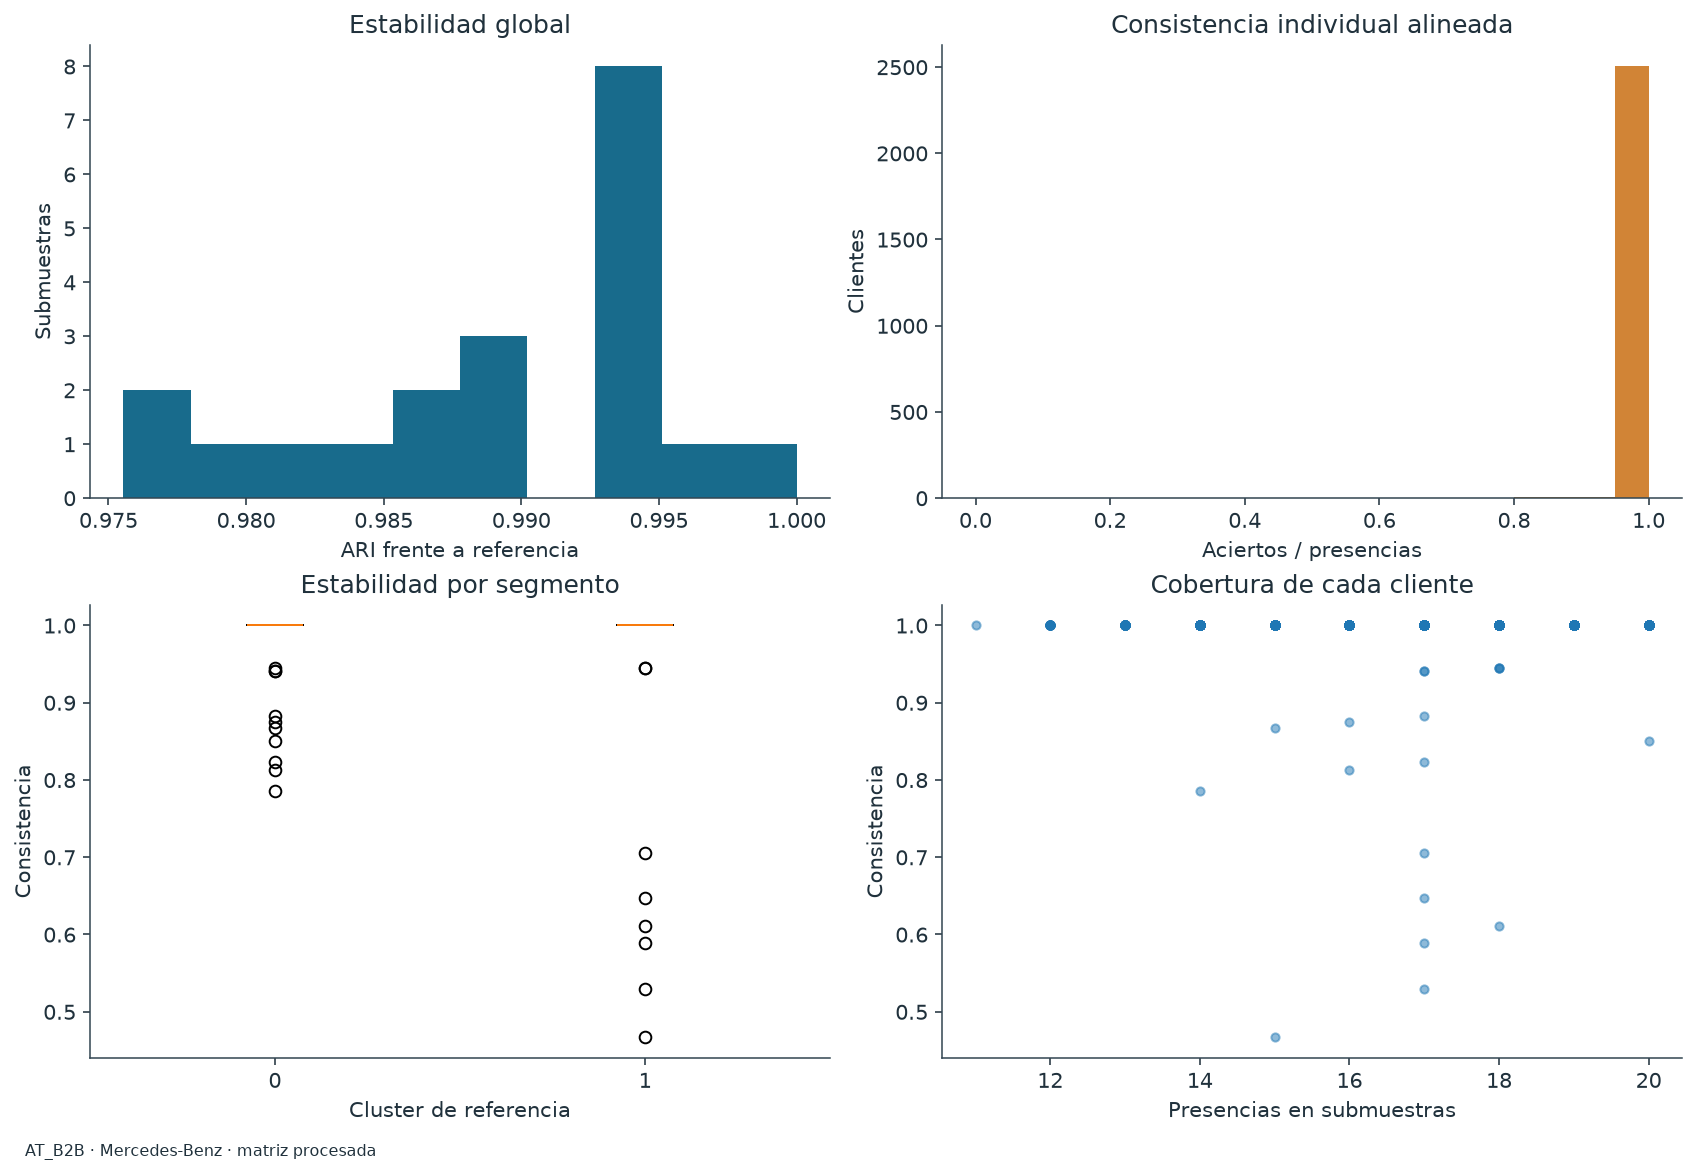

AT_B2C · consistencia por cluster


,Cluster,Clientes,n_unseen,Consistencia media,pooled_agreement,Fracción inestable,total_presences
0,0,10194,0,0.9973,0.9973,0.0059,173431
1,1,27404,0,0.9987,0.9987,0.0023,465860
2,2,35433,0,0.9980,0.9980,0.0041,602424
3,3,8794,0,0.9988,0.9988,0.0028,149555
4,4,13687,0,0.9987,0.9987,0.0025,232423
5,5,11938,0,0.9985,0.9985,0.0027,202947


AT_B2C · cola de inestabilidad


,iteration,ari,aligned_agreement,reference_clusters_present,unmatched_fraction
0,0,0.9970,0.9989,6,0.0
1,1,0.9965,0.9986,6,0.0
2,2,0.9933,0.9972,6,0.0
3,3,0.9944,0.9976,6,0.0
4,4,0.9962,0.9986,6,0.0
5,5,0.9963,0.9984,6,0.0
6,6,0.9929,0.9972,6,0.0
7,7,0.9966,0.9985,6,0.0
8,8,0.9971,0.9988,6,0.0
9,9,0.9968,0.9987,6,0.0


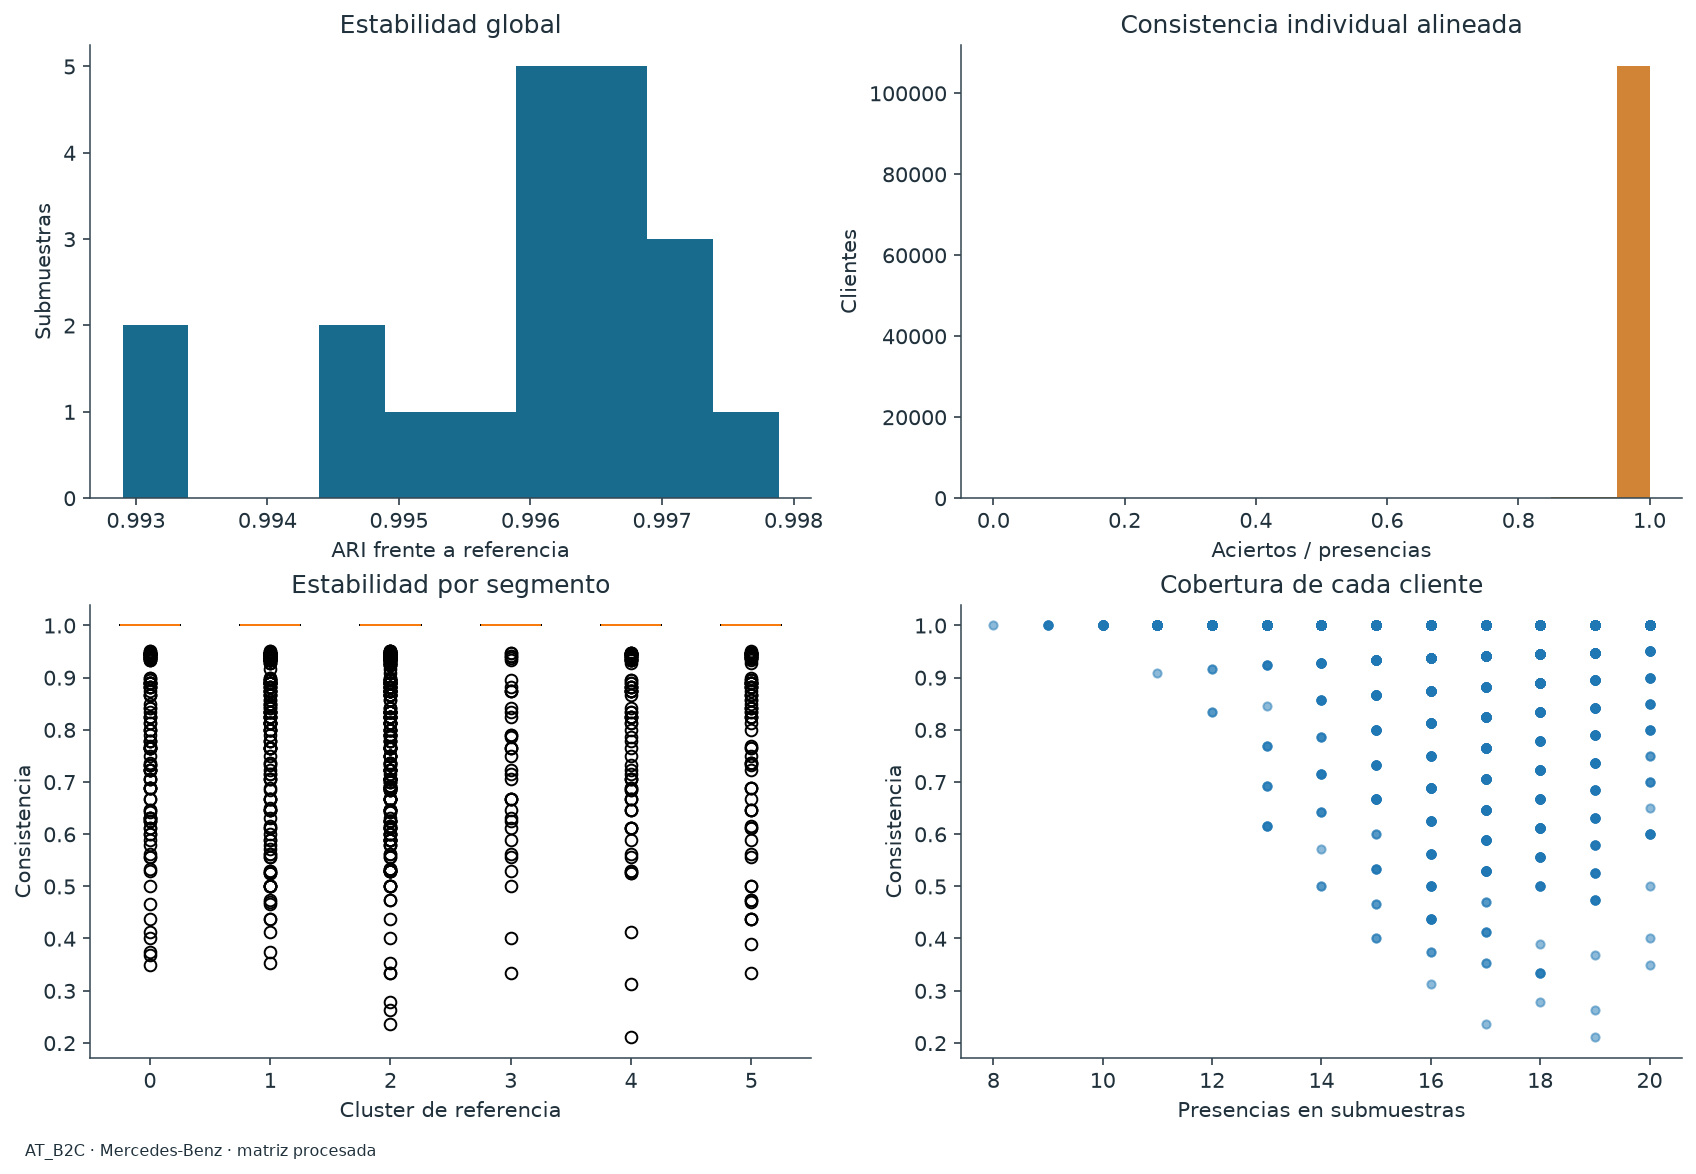

CH_B2B · consistencia por cluster


,Cluster,Clientes,n_unseen,Consistencia media,pooled_agreement,Fracción inestable,total_presences
0,0,2864,0,0.9943,0.9943,0.0157,48664
1,1,135,0,0.9737,0.9719,0.0519,2316


CH_B2B · cola de inestabilidad


,iteration,ari,aligned_agreement,reference_clusters_present,unmatched_fraction
0,0,0.9663,0.9973,2,0.0
1,1,0.8247,0.9843,2,0.0
2,2,0.8419,0.9859,2,0.0
3,3,0.9747,0.9980,2,0.0
4,4,0.9747,0.9980,2,0.0
5,5,0.9690,0.9976,2,0.0
6,6,1.0000,1.0000,2,0.0
7,7,0.9653,0.9973,2,0.0
8,8,0.9903,0.9992,2,0.0
9,9,0.9640,0.9973,2,0.0


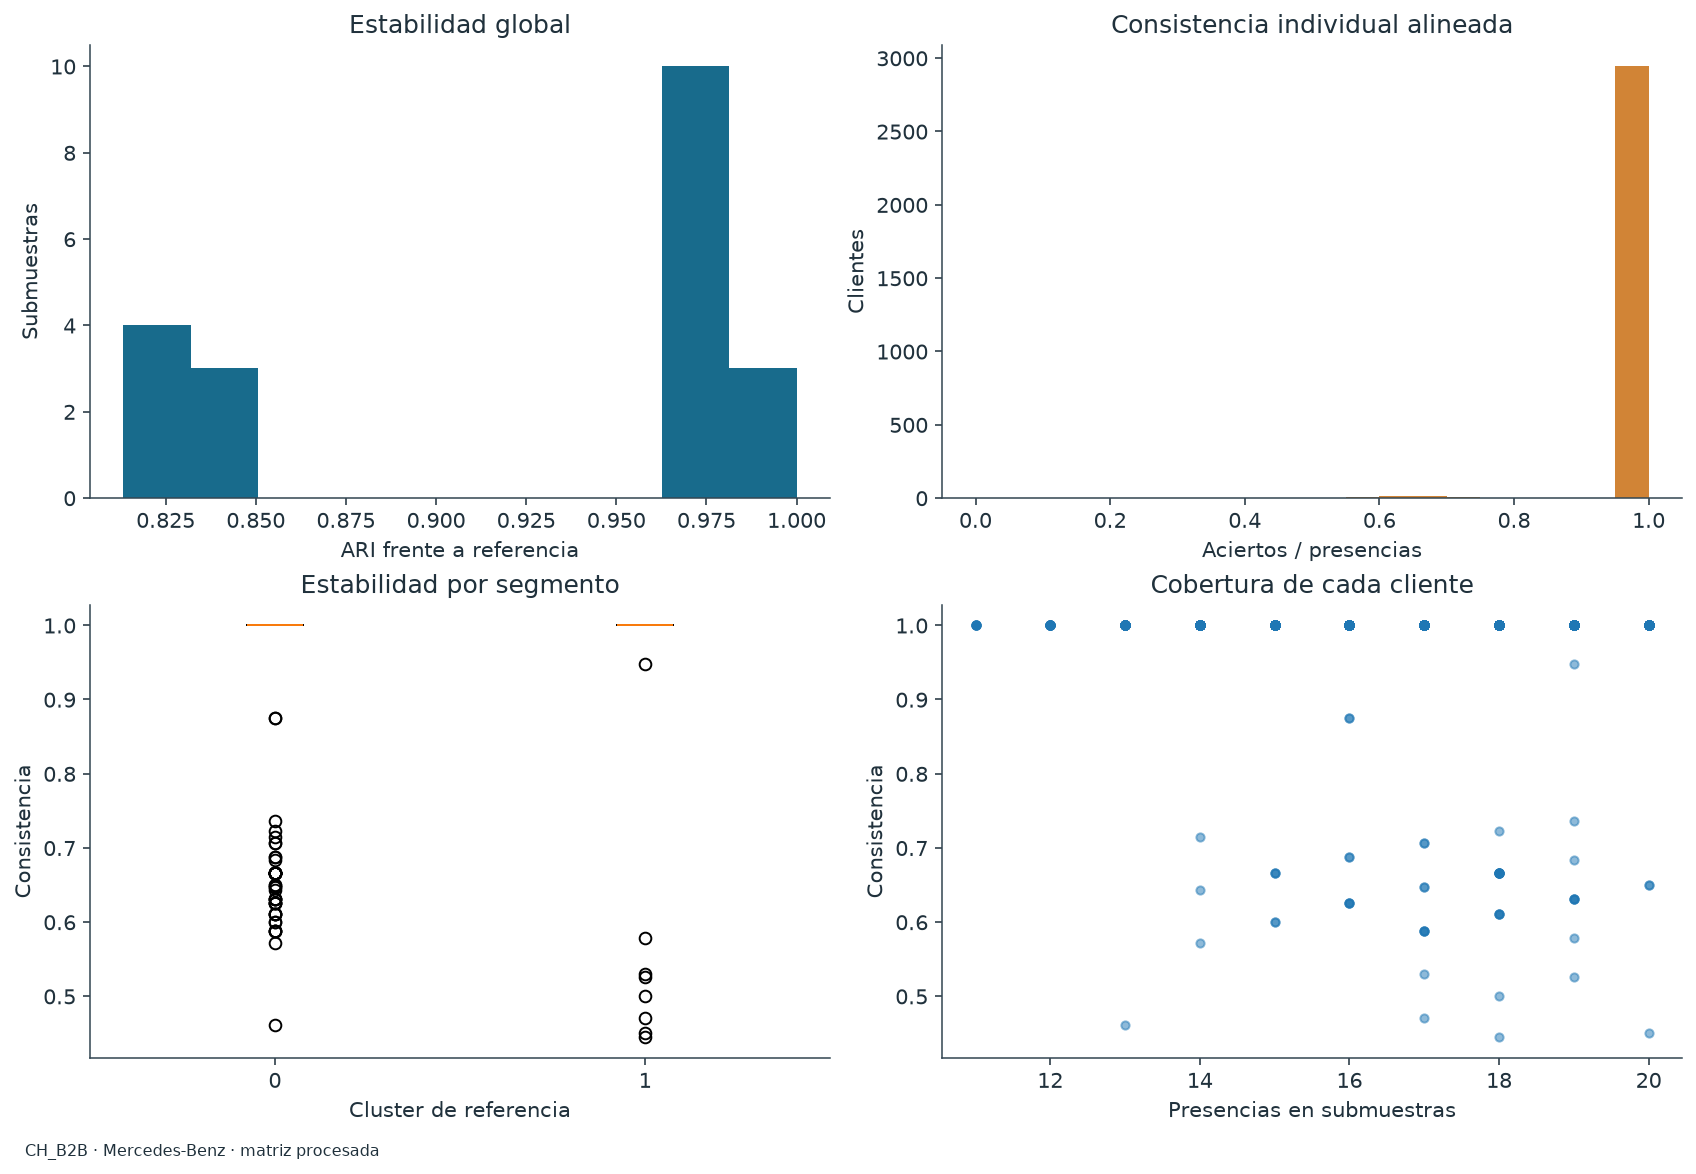

CH_B2C · consistencia por cluster


,Cluster,Clientes,n_unseen,Consistencia media,pooled_agreement,Fracción inestable,total_presences
0,0,27389,0,0.9968,0.9968,0.0065,465576
1,1,66897,0,0.9858,0.9858,0.0267,1137265
2,2,53360,0,0.9858,0.9859,0.0312,907601
3,3,33651,0,0.9950,0.9950,0.0092,571745
4,4,8582,0,0.9985,0.9986,0.0034,145753


CH_B2C · cola de inestabilidad


,iteration,ari,aligned_agreement,reference_clusters_present,unmatched_fraction
0,0,0.9920,0.9971,5,0.0
1,1,0.9709,0.9901,5,0.0
2,2,0.9951,0.9982,5,0.0
3,3,0.9881,0.9960,5,0.0
4,4,0.9365,0.9786,5,0.0
5,5,0.9867,0.9956,5,0.0
6,6,0.9484,0.9828,5,0.0
7,7,0.9957,0.9985,5,0.0
8,8,0.9879,0.9958,5,0.0
9,9,0.9439,0.9813,5,0.0


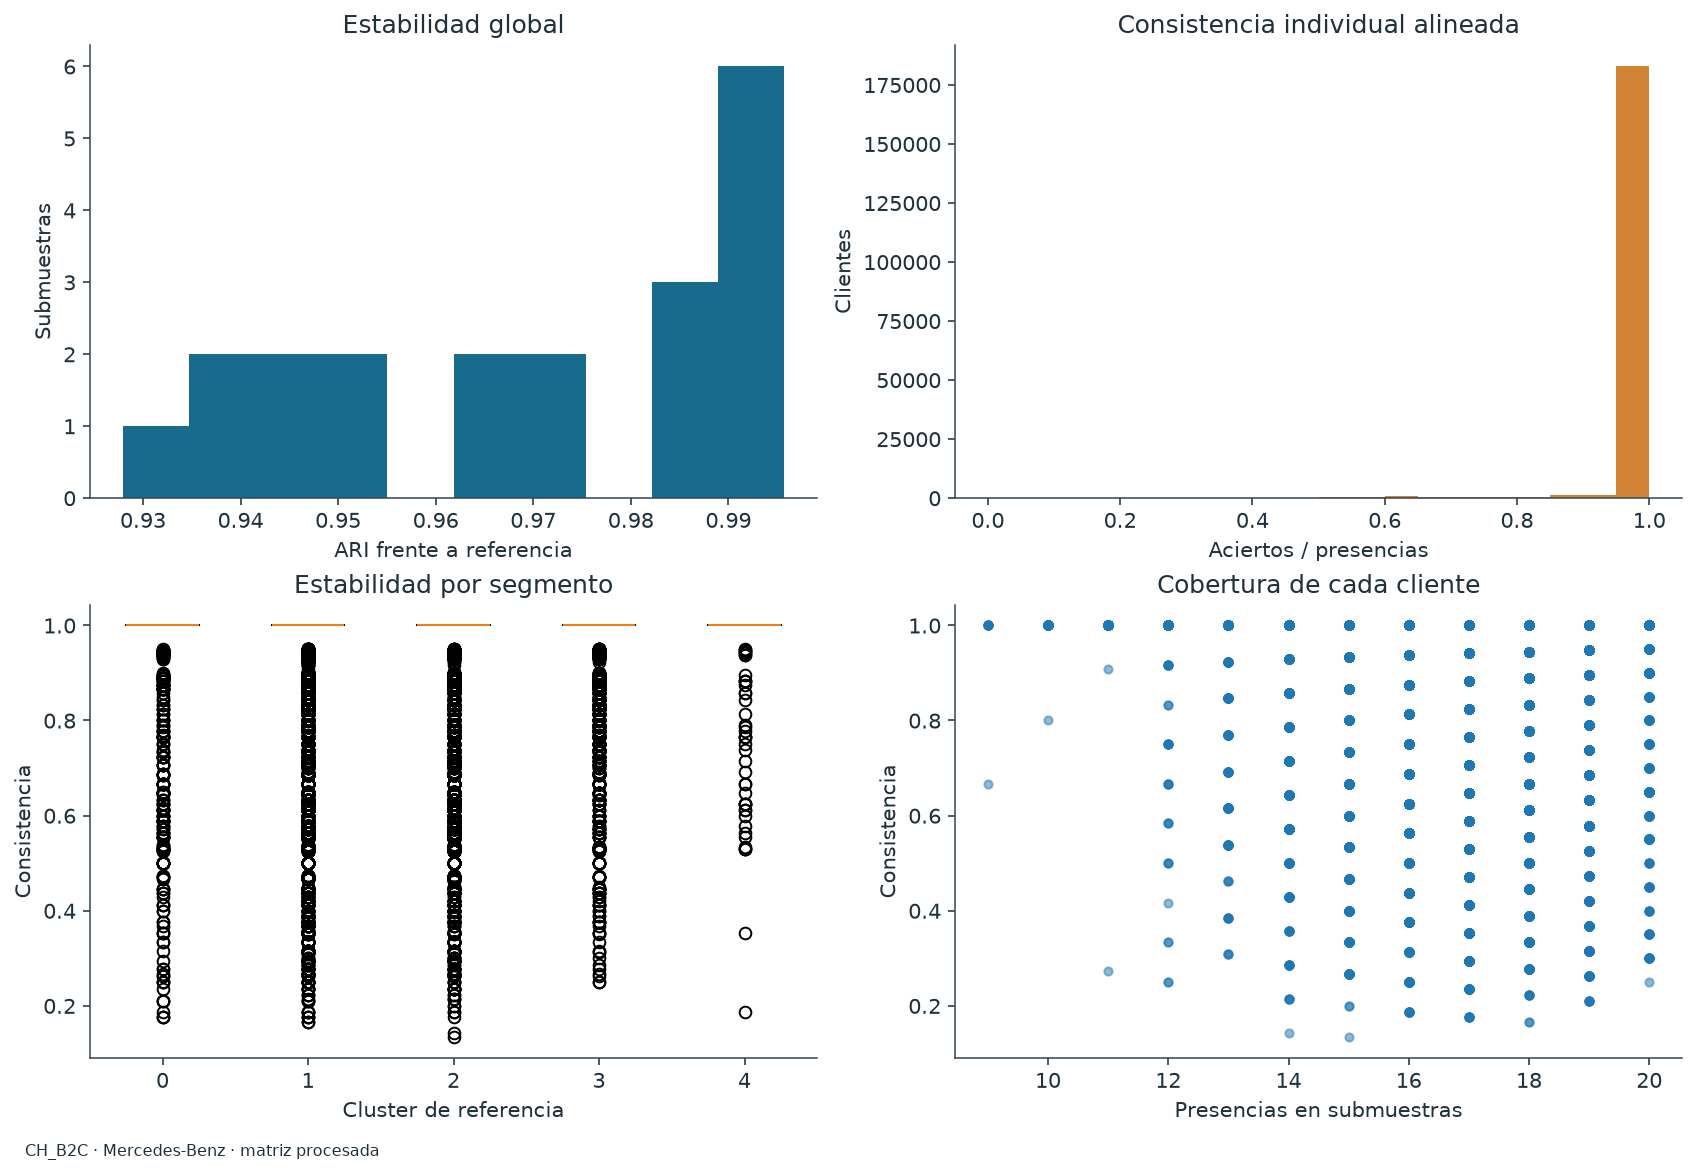

In [15]:
for segment, context in analyses.items():
    result=context["jackknife"]
    display_table(result.clusters,segment+" · consistencia por cluster")
    display_table(result.iterations[["iteration","ari","aligned_agreement","reference_clusters_present","unmatched_fraction"]],
        segment+" · cola de inestabilidad",max_rows=N_RESAMPLES)
    plot_stability(result)
    show_figures(segment)


## Diseño de escenarios orientados a eventos

Se prueban tres familias. **Error de medición:** ruido en una lista explícita de variables, con escala IQR/1.349 y respaldo en desviación estándar; no se alteran flags ni códigos de edad. **Dependencia de la coordenada separadora:** se contrae la variable con mayor dispersión entre medias de clusters, ponderada por tamaños; con varianzas unitarias, elegir el máximo de varianza total sería un empate numérico. **Cambio de cobertura:** exclusión dirigida al segmento menor. Se mantienen fijos los parámetros de escala de 03 durante Jackknife y estrés: se evalúa robustez condicional a esa representación, no la incertidumbre de estimar de nuevo el preprocesamiento. Los CSV permanecen intactos.


In [16]:
scenarios_table=pd.DataFrame([
    ("measurement_noise","5 % y 15 % de dispersión robusta","Sensibilidad a medición en coordenadas procesadas"),
    ("dominant_feature","Contracción 10 % y 30 %","Dependencia de la representación dominante"),
    ("minority_attrition","Excluir 30 % y 60 % del grupo menor","Cambio de composición y cobertura"),
],columns=["Familia","Intensidades","Pregunta"])
display_table(scenarios_table,"Escenarios fijados antes de interpretar resultados")


Escenarios fijados antes de interpretar resultados


,Familia,Intensidades,Pregunta
0,measurement_noise,5 % y 15 % de dispersión robusta,Sensibilidad a medición en coordenadas procesadas
1,dominant_feature,Contracción 10 % y 30 %,Dependencia de la representación dominante
2,minority_attrition,Excluir 30 % y 60 % del grupo menor,Cambio de composición y cobertura


## Respuesta vigente, reajuste y anclas intactas

Para cada escenario se distingue: asignación con centros vigentes, partición tras reentrenar y predicción del modelo nuevo sobre las mismas anclas originales sin alterar. Esta última aísla el movimiento de fronteras de los cambios del cliente. Las anclas son una muestra uniforme de hasta 1.000 IDs, comparados solo si permanecen presentes. Los controles de intensidad cero reutilizan el modelo. Hay tres repeticiones en escenarios aleatorios y una en la contracción determinista, evitando ajustes idénticos.


In [17]:
for segment, context in analyses.items():
    context["stress_feature"] = most_separating_feature(context["data"],context["labels"])
    context["stress"]=perturbation_study(context["data"],context["model"],scenarios=SCENARIOS,
        repeats=SCENARIO_REPEATS,random_state=SEED,noise_features=NOISE_FEATURES,
        graph_anchors=GRAPH_ANCHORS,graph_neighbors=GRAPH_NEIGHBORS,dominant_feature=context["stress_feature"])
    keep_table(segment,"escenarios completos",context["stress"].runs)
    keep_table(segment,"consistencia por escenario y cliente",context["stress"].clients)


## Cuánto cambia cada partición

Las bandas muestran mínimo y máximo entre repeticiones; no son intervalos de confianza. La exclusión dirigida usa únicamente clientes presentes, sin atribuir estabilidad a los excluidos. Las intensidades de familias distintas no son intercambiables.


AT_B2B · respuesta al estrés


frozen_ari          ... untouched_anchor_ari        
                                  mean     min  ...                  min     max
family             severity                     ...                             
dominant_feature   0.00         1.0000  1.0000  ...               1.0000  1.0000
                   0.10         0.9824  0.9824  ...               0.9848  0.9848
                   0.30         0.9433  0.9433  ...               0.8637  0.8637
measurement_noise  0.00         1.0000  1.0000  ...               1.0000  1.0000
                   0.05         0.9990  0.9971  ...               0.9924  1.0000
                   0.15         0.9951  0.9942  ...               0.9924  1.0000
minority_attrition 0.00         1.0000  1.0000  ...               1.0000  1.0000
                   0.30         1.0000  1.0000  ...               0.1796  0.1910
                   0.60         1.0000  1.0000  ...               0.1038  0.1178

[9 rows x 9 columns]

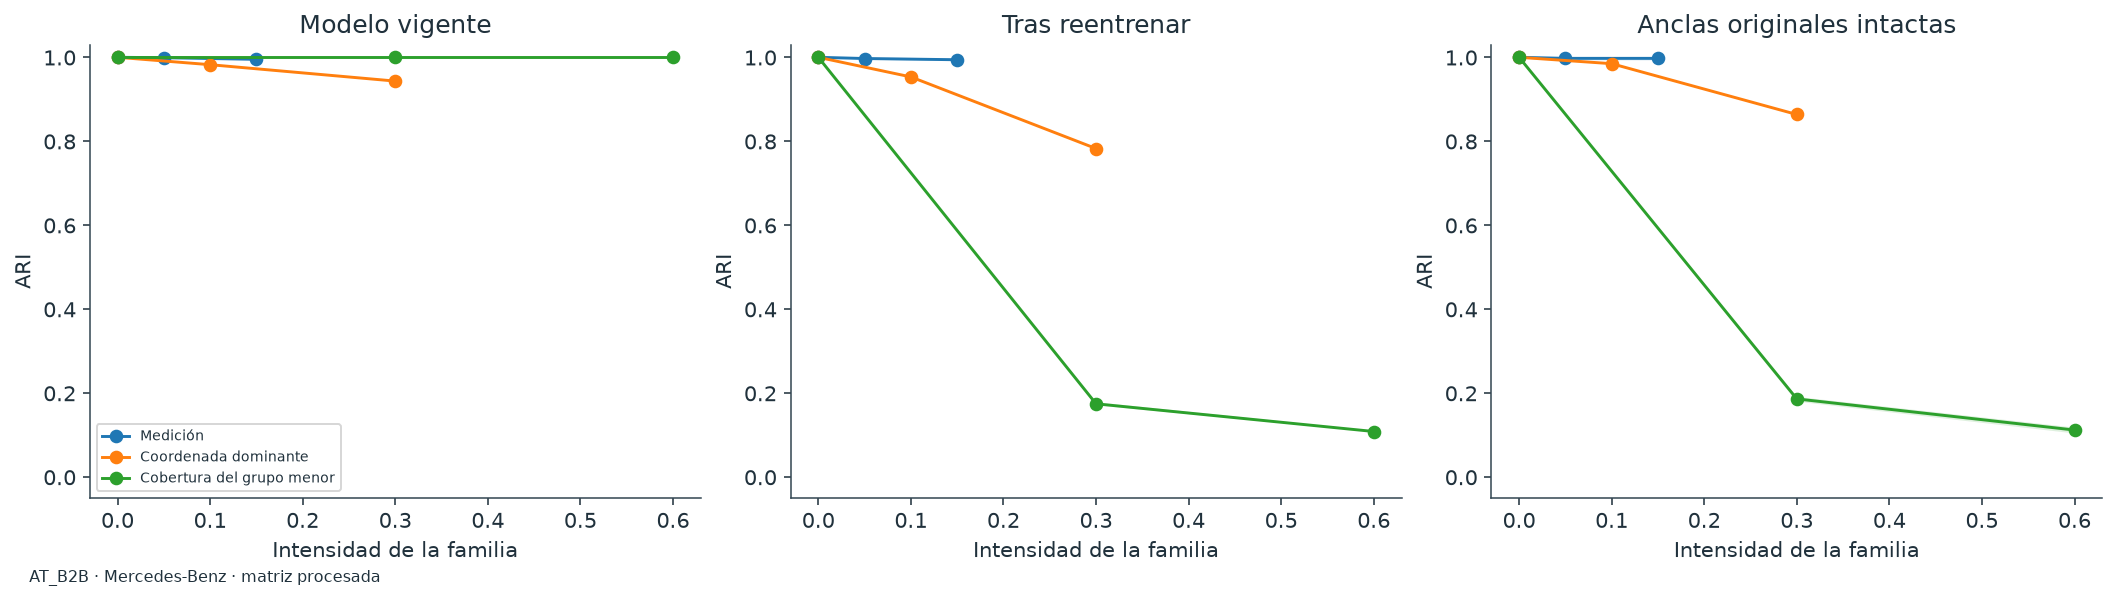

AT_B2C · respuesta al estrés


frozen_ari          ... untouched_anchor_ari        
                                  mean     min  ...                  min     max
family             severity                     ...                             
dominant_feature   0.00         1.0000  1.0000  ...               1.0000  1.0000
                   0.10         0.9894  0.9894  ...               0.9988  0.9988
                   0.30         0.9617  0.9617  ...               0.4481  0.4481
measurement_noise  0.00         1.0000  1.0000  ...               1.0000  1.0000
                   0.05         0.9949  0.9948  ...               1.0000  1.0000
                   0.15         0.9829  0.9827  ...               0.9973  1.0000
minority_attrition 0.00         1.0000  1.0000  ...               1.0000  1.0000
                   0.30         1.0000  1.0000  ...               0.9965  1.0000
                   0.60         1.0000  1.0000  ...               0.4933  0.4982

[9 rows x 9 columns]

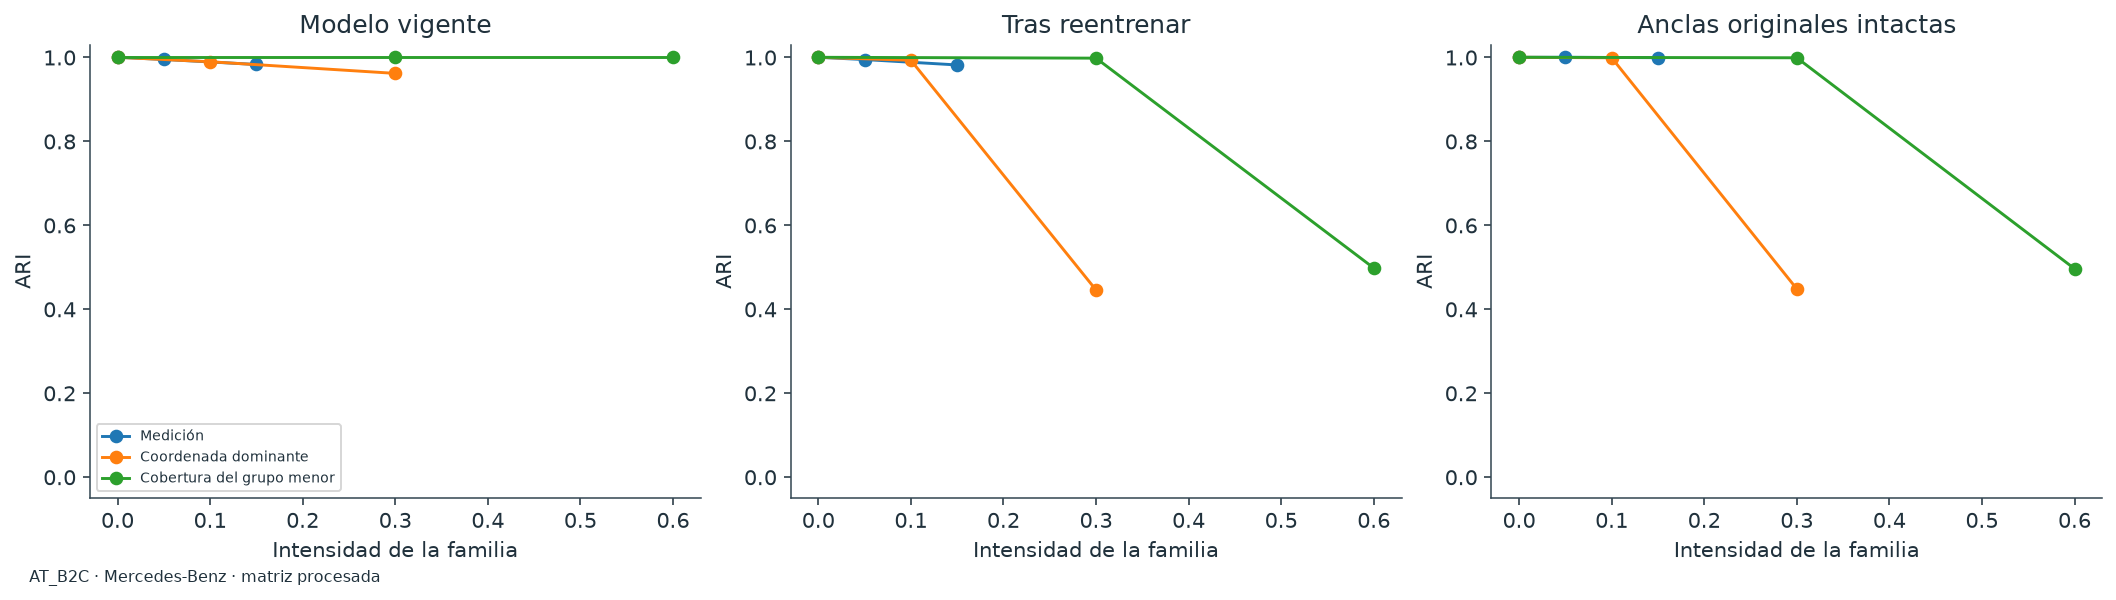

CH_B2B · respuesta al estrés


frozen_ari          ... untouched_anchor_ari        
                                  mean     min  ...                  min     max
family             severity                     ...                             
dominant_feature   0.00         1.0000  1.0000  ...               1.0000  1.0000
                   0.10         0.9915  0.9915  ...               0.8470  0.8470
                   0.30         0.9785  0.9785  ...               0.8368  0.8368
measurement_noise  0.00         1.0000  1.0000  ...               1.0000  1.0000
                   0.05         0.9986  0.9957  ...               0.9864  1.0000
                   0.15         0.9957  0.9915  ...               0.9864  1.0000
minority_attrition 0.00         1.0000  1.0000  ...               1.0000  1.0000
                   0.30         1.0000  1.0000  ...               0.7562  0.7618
                   0.60         1.0000  1.0000  ...               0.2462  0.2932

[9 rows x 9 columns]

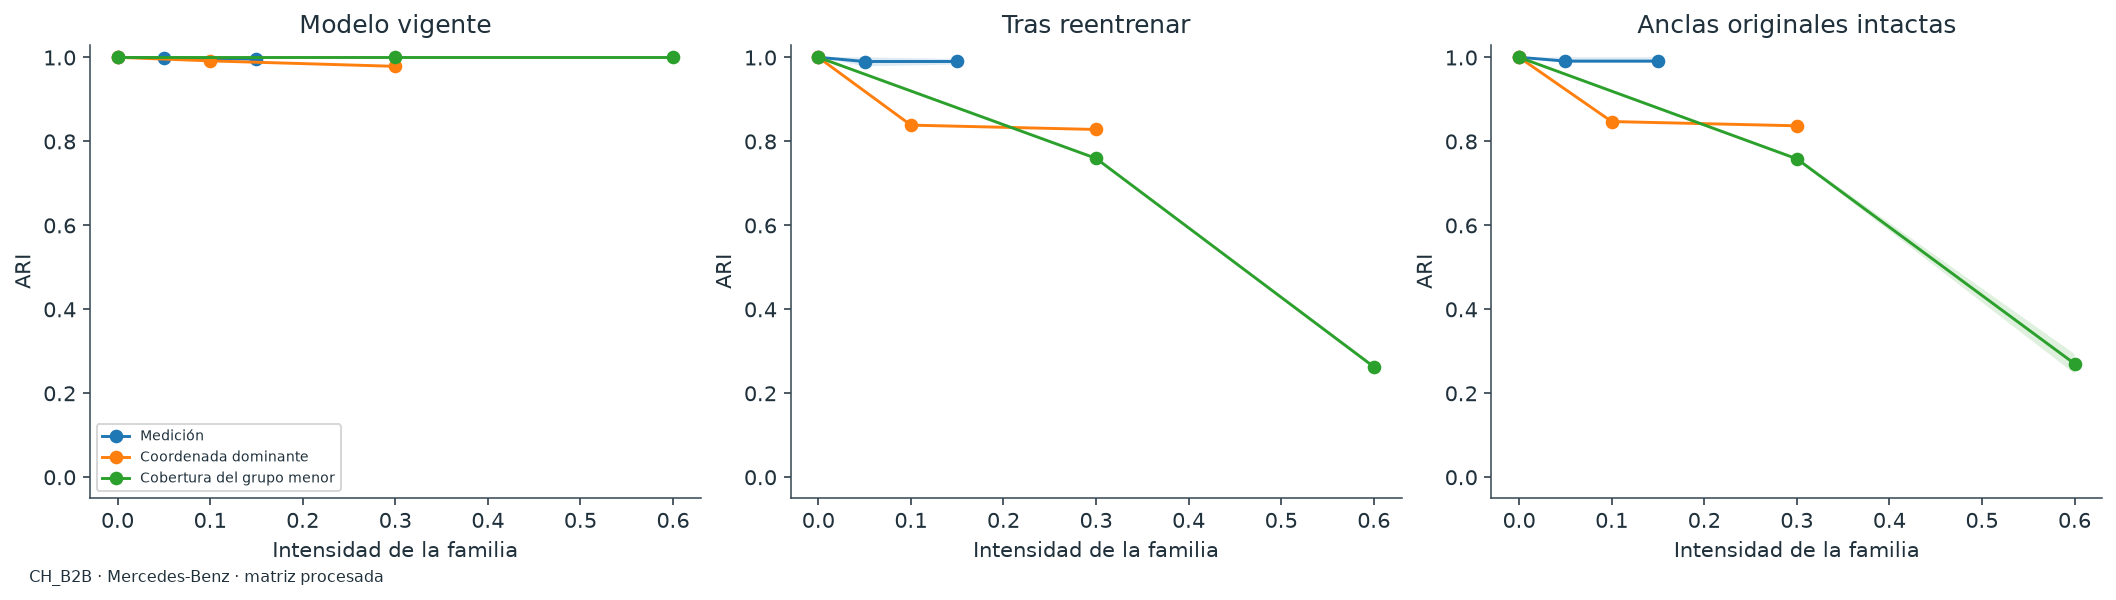

CH_B2C · respuesta al estrés


frozen_ari          ... untouched_anchor_ari        
                                  mean     min  ...                  min     max
family             severity                     ...                             
dominant_feature   0.00         1.0000  1.0000  ...               1.0000  1.0000
                   0.10         0.9952  0.9952  ...               0.9984  0.9984
                   0.30         0.9830  0.9830  ...               0.6836  0.6836
measurement_noise  0.00         1.0000  1.0000  ...               1.0000  1.0000
                   0.05         0.9856  0.9854  ...               0.9754  0.9901
                   0.15         0.9564  0.9562  ...               0.8706  0.9803
minority_attrition 0.00         1.0000  1.0000  ...               1.0000  1.0000
                   0.30         1.0000  1.0000  ...               0.6884  0.6976
                   0.60         1.0000  1.0000  ...               0.7357  0.7517

[9 rows x 9 columns]

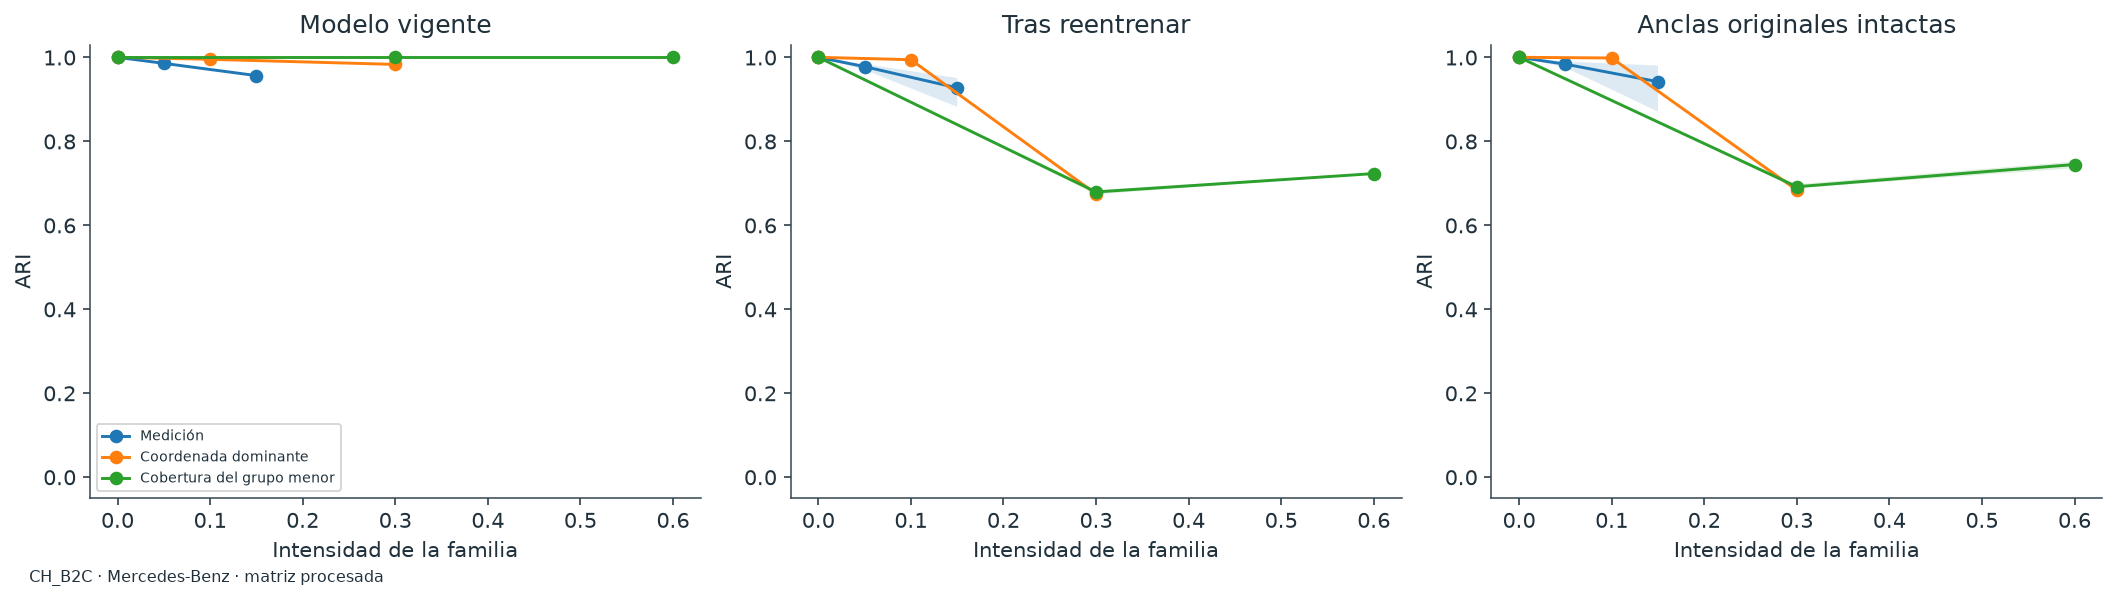

In [18]:
for segment, context in analyses.items():
    runs=context["stress"].runs
    summary=runs.groupby(["family","severity"])[["frozen_ari","refit_ari","untouched_anchor_ari"]].agg(["mean","min","max"])
    display_table(summary,segment+" · respuesta al estrés",max_rows=12)
    fig,axes=plt.subplots(1,3,figsize=(15,4),layout="constrained")
    for ax,metric,title in zip(axes,["frozen_ari","refit_ari","untouched_anchor_ari"],
        ["Modelo vigente","Tras reentrenar","Anclas originales intactas"]):
        for family,group in runs.groupby("family",sort=False):
            curve=group.groupby("severity")[metric].agg(["mean","min","max"])
            family_label={"measurement_noise":"Medición","dominant_feature":"Coordenada dominante",
                          "minority_attrition":"Cobertura del grupo menor"}[family]
            ax.plot(curve.index,curve["mean"],"o-",label=family_label)
            ax.fill_between(curve.index,curve["min"],curve["max"],alpha=.15)
        ax.set(xlabel="Intensidad de la familia",ylabel="ARI",title=title,ylim=(-.05,1.03))
    axes[0].legend(fontsize=7)
    show_figures(segment)


## Qué segmentos cambian bajo cada escenario

El ARI global puede ocultar cambios importantes en un grupo pequeño. Se informa el menor Jaccard de pertenencia tras alinear, junto a la retención y la cantidad de clientes de referencia presentes. Las exclusiones no se cuentan como desacuerdo. Si un grupo no está representado, su estabilidad es desconocida.


In [19]:
for segment, context in analyses.items():
    groups=context["stress"].clusters.loc[lambda frame:frame["severity"]>0]
    summary=groups.groupby(["family","cluster"]).agg(
        worst_membership_jaccard=("membership_jaccard","min"),
        mean_retained_fraction=("retained_fraction","mean"),
        min_reference_present=("n_reference_present","min"))
    display_table(summary,segment+" · segmentos sensibles al cambio",max_rows=24)
    context["worst_cluster_jaccard"]=groups.groupby("cluster")["membership_jaccard"].min()
    keep_table(segment,"pertenencia por escenario y cluster",groups)


AT_B2B · segmentos sensibles al cambio


worst_membership_jaccard  ...  min_reference_present
family             cluster                            ...                       
dominant_feature   0                          0.9712  ...                   2297
                   1                          0.6978  ...                    225
measurement_noise  0                          0.9987  ...                   2297
                   1                          0.9867  ...                    225
minority_attrition 0                          0.7535  ...                   2297
                   1                          0.1181  ...                     90

[6 rows x 3 columns]

AT_B2C · segmentos sensibles al cambio


worst_membership_jaccard  ...  min_reference_present
family             cluster                            ...                       
dominant_feature   0                          0.8379  ...                  10194
                   1                          0.4373  ...                  27404
                   2                          0.4634  ...                  35433
                   3                          0.0216  ...                   8794
                   4                          0.8409  ...                  13687
                   5                          0.8947  ...                  11938
measurement_noise  0                          0.9706  ...                  10194
                   1                          0.9847  ...                  27404
                   2                          0.9861  ...                  35433
                   3                          0.9852  ...                   8794
                   4                          0.9894  ...                  13687
                   5                          0.9868  ...                  11938
minority_attrition 0                          0.8323  ...                  10194
                   1                          0.5697  ...                  27404
                   2                          0.4735  ...                  35433
                   3                          0.0091  ...                   3518
                   4                          0.8712  ...                  13687
                   5                          0.9118  ...                  11938

[18 rows x 3 columns]

CH_B2B · segmentos sensibles al cambio


worst_membership_jaccard  ...  min_reference_present
family             cluster                            ...                       
dominant_feature   0                          0.9836  ...                   2864
                   1                          0.7403  ...                    135
measurement_noise  0                          0.9983  ...                   2864
                   1                          0.9630  ...                    135
minority_attrition 0                          0.9166  ...                   2864
                   1                          0.1815  ...                     54

[6 rows x 3 columns]

CH_B2C · segmentos sensibles al cambio


worst_membership_jaccard  ...  min_reference_present
family             cluster                            ...                       
dominant_feature   0                          0.9122  ...                  27389
                   1                          0.7271  ...                  66897
                   2                          0.7681  ...                  53360
                   3                          0.8075  ...                  33651
                   4                          0.0380  ...                   8582
measurement_noise  0                          0.9792  ...                  27389
                   1                          0.9022  ...                  66897
                   2                          0.8982  ...                  53360
                   3                          0.9414  ...                  33651
                   4                          0.9884  ...                   8582
minority_attrition 0                          0.9211  ...                  27389
                   1                          0.7222  ...                  66897
                   2                          0.7705  ...                  53360
                   3                          0.8042  ...                  33651
                   4                          0.0180  ...                   3433

[15 rows x 3 columns]

## Estabilidad estructural de vecindarios y conexiones

Se construye un grafo k-NN disperso sobre las mismas anclas en X y X alterada. Se compara Jaccard de aristas y adyacencias entre segmentos alineados. Tras excluir filas, se reconstruye la referencia sobre la intersección de IDs; los radios se fijan con esa referencia pareada. Se filtran aristas a tres cuantiles de distancias, midiendo componentes conexas y masa de la mayor. Es un diagnóstico topológico aproximado del grafo, **no homología persistente ni una prueba de topología poblacional**. Sin aristas entre segmentos, Jaccard=1 es trivial; se informan cantidades y cobertura. Los empates y duplicados pueden modificar vecindarios sin cambiar la partición.


In [20]:
for segment, context in analyses.items():
    runs=context["stress"].runs
    graph_view=runs.groupby(["family","severity"])[["neighbor_edge_jaccard","segment_adjacency_jaccard",
        "reference_segment_edges","altered_segment_edges","zero_distance_edge_fraction","graph_anchor_n",
        "graph_reference_clusters_seen","graph_altered_clusters_seen"]].mean()
    display_table(graph_view,segment+" · sensibilidad del grafo",max_rows=12)
    scales=context["stress"].topology_scales.copy()
    scales["component_change"]=scales["altered_components"]-scales["reference_components"]
    view=scales.groupby(["family","severity","distance_quantile"])[["radius_edge_jaccard","component_change",
        "reference_largest_fraction","altered_largest_fraction"]].mean()
    display_table(view,segment+" · sensibilidad a la escala del grafo",max_rows=27)
    keep_table(segment,"estructura multiescala",scales)


AT_B2B · sensibilidad del grafo


neighbor_edge_jaccard  ...  graph_altered_clusters_seen
family             severity                         ...                             
dominant_feature   0.00                     1.0000  ...                          2.0
                   0.10                     0.9802  ...                          2.0
                   0.30                     0.9284  ...                          2.0
measurement_noise  0.00                     1.0000  ...                          2.0
                   0.05                     0.8504  ...                          2.0
                   0.15                     0.7070  ...                          2.0
minority_attrition 0.00                     1.0000  ...                          2.0
                   0.30                     1.0000  ...                          2.0
                   0.60                     1.0000  ...                          2.0

[9 rows x 8 columns]

AT_B2B · sensibilidad a la escala del grafo


radius_edge_jaccard  ...  altered_largest_fraction
family             severity distance_quantile                       ...                          
dominant_feature   0.00     0.50                            1.0000  ...                    0.1170
                            0.75                            1.0000  ...                    0.5030
                            0.90                            1.0000  ...                    0.9580
                   0.10     0.50                            1.0000  ...                    0.1170
                            0.75                            1.0000  ...                    0.5030
                            0.90                            0.9876  ...                    0.9590
                   0.30     0.50                            0.9985  ...                    0.1170
                            0.75                            0.9958  ...                    0.5200
                            0.90                            0.9462  ...                    0.9400
measurement_noise  0.00     0.50                            1.0000  ...                    0.1170
                            0.75                            1.0000  ...                    0.5030
                            0.90                            1.0000  ...                    0.9580
                   0.05     0.50                            0.8374  ...                    0.1227
                            0.75                            0.8343  ...                    0.5037
                            0.90                            0.8416  ...                    0.9583
                   0.15     0.50                            0.6793  ...                    0.1563
                            0.75                            0.6796  ...                    0.6440
                            0.90                            0.6931  ...                    0.9567
minority_attrition 0.00     0.50                            1.0000  ...                    0.1170
                            0.75                            1.0000  ...                    0.5030
                            0.90                            1.0000  ...                    0.9580
                   0.30     0.50                            1.0000  ...                    0.1003
                            0.75                            1.0000  ...                    0.4706
                            0.90                            1.0000  ...                    0.9550
                   0.60     0.50                            1.0000  ...                    0.0982
                            0.75                            1.0000  ...                    0.4604
                            0.90                            1.0000  ...                    0.8789

[27 rows x 4 columns]

AT_B2C · sensibilidad del grafo


...

radius_edge_jaccard  ...  altered_largest_fraction
family             severity distance_quantile                       ...                          
dominant_feature   0.00     0.50                            1.0000  ...                    0.4030
                            0.75                            1.0000  ...                    0.8020
                            0.90                            1.0000  ...                    0.8840
                   0.10     0.50                            1.0000  ...                    0.4030
                            0.75                            0.9990  ...                    0.8020
                            0.90                            0.9994  ...                    0.8840
                   0.30     0.50                            0.9985  ...                    0.4030
                            0.75                            0.9985  ...                    0.8020
                            0.90                            0.9981  ...                    0.8840
measurement_noise  0.00     0.50                            1.0000  ...                    0.4030
                            0.75                            1.0000  ...                    0.8020
                            0.90                            1.0000  ...                    0.8840
                   0.05     0.50                            0.8913  ...                    0.4003
                            0.75                            0.8760  ...                    0.8013
                            0.90                            0.8745  ...                    0.8840
                   0.15     0.50                            0.7348  ...                    0.4357
                            0.75                            0.7177  ...                    0.7970
                            0.90                            0.7223  ...                    0.8847
minority_attrition 0.00     0.50                            1.0000  ...                    0.4030
                            0.75                            1.0000  ...                    0.8020
                            0.90                            1.0000  ...                    0.8840
                   0.30     0.50                            1.0000  ...                    0.3978
                            0.75                            1.0000  ...                    0.8023
                            0.90                            1.0000  ...                    0.8932
                   0.60     0.50                            1.0000  ...                    0.3347
                            0.75                            1.0000  ...                    0.8131
                            0.90                            1.0000  ...                    0.9035

[27 rows x 4 columns]

CH_B2C · sensibilidad del grafo


neighbor_edge_jaccard  ...  graph_altered_clusters_seen
family             severity                         ...                             
dominant_feature   0.00                     1.0000  ...                          5.0
                   0.10                     0.9798  ...                          5.0
                   0.30                     0.9267  ...                          5.0
measurement_noise  0.00                     1.0000  ...                          5.0
                   0.05                     0.9151  ...                          5.0
                   0.15                     0.7917  ...                          5.0
minority_attrition 0.00                     1.0000  ...                          5.0
                   0.30                     1.0000  ...                          5.0
                   0.60                     1.0000  ...                          5.0

[9 rows x 8 columns]

CH_B2C · sensibilidad a la escala del grafo


radius_edge_jaccard  ...  altered_largest_fraction
family             severity distance_quantile                       ...                          
dominant_feature   0.00     0.50                            1.0000  ...                    0.7170
                            0.75                            1.0000  ...                    0.9030
                            0.90                            1.0000  ...                    0.9610
                   0.10     0.50                            0.9826  ...                    0.7180
                            0.75                            0.9800  ...                    0.9060
                            0.90                            0.9811  ...                    0.9610
                   0.30     0.50                            0.9457  ...                    0.7300
                            0.75                            0.9415  ...                    0.9140
                            0.90                            0.9358  ...                    0.9630
measurement_noise  0.00     0.50                            1.0000  ...                    0.7170
                            0.75                            1.0000  ...                    0.9030
                            0.90                            1.0000  ...                    0.9610
                   0.05     0.50                            0.9054  ...                    0.7167
                            0.75                            0.9129  ...                    0.9037
                            0.90                            0.9126  ...                    0.9620
                   0.15     0.50                            0.7660  ...                    0.7140
                            0.75                            0.7807  ...                    0.9050
                            0.90                            0.7849  ...                    0.9633
minority_attrition 0.00     0.50                            1.0000  ...                    0.7170
                            0.75                            1.0000  ...                    0.9030
                            0.90                            1.0000  ...                    0.9610
                   0.30     0.50                            1.0000  ...                    0.7213
                            0.75                            1.0000  ...                    0.9036
                            0.90                            1.0000  ...                    0.9609
                   0.60     0.50                            1.0000  ...                    0.7292
                            0.75                            1.0000  ...                    0.9020
                            0.90                            1.0000  ...                    0.9594

[27 rows x 4 columns]

## Candidatos consistentes y clientes para revisión

Se cruzan señales distintas: consistencia Jackknife ≥0.8 con cobertura suficiente; cambio tras reajuste ≤20 % de los escenarios de cada familia; Jaccard de su cluster ≥0.75 incluso en el peor escenario; ausencia de alerta de frontera de 03 y de ambigüedad/desacuerdo GMM de 05. Además, se exige una hipótesis diferenciada en 04 y que todos los ARI globales de Jackknife, reajuste y anclas intactas superen 0.8. Es una regla conservadora de revisión, no una autorización de campaña ni una probabilidad. La frecuencia en el grid depende del diseño de escenarios. Las señales desconocidas no se tratan como favorables.


In [21]:
for segment, context in analyses.items():
    arrays=context["entry"]["arrays"]
    if not {"gmm_disagreement","gmm_ambiguous"}.issubset(arrays):
        raise ValueError("Completar la entrega 05 y utilizar su paquete actualizado antes de 07.")
    if "campaign_eligibility" not in context["entry"]:
        raise ValueError("Completar la interpretación 04 para vincular audiencia e hipótesis.")
    risk=context["jackknife"].clients.merge(context["stress"].clients,on=["client_id","cluster"],validate="one_to_one")
    change_columns=[column for column in risk if column.endswith("_refit_change_fraction")]
    risk["max_scenario_change"]=risk[change_columns].max(axis=1)
    risk["all_families_observed"]=risk[change_columns].notna().all(axis=1)
    risk["worst_cluster_jaccard"]=risk["cluster"].map(context["worst_cluster_jaccard"])
    risk["boundary_review"]=context["clients"]["near_boundary"].to_numpy()
    risk["model_review"]=arrays["gmm_disagreement"] | arrays["gmm_ambiguous"]
    risk["profile_supported"]=risk["cluster"].map(lambda value:context["entry"]["campaign_eligibility"].get(str(value),False))
    risk["pilot_candidate"]=(~risk["insufficient_presence"] & (risk["stability"]>=MIN_CLIENT_STABILITY)
        & risk["all_families_observed"] & (risk["max_scenario_change"]<=MAX_GRID_CHANGE_FRACTION)
        & (risk["worst_cluster_jaccard"]>=MIN_CLUSTER_JACCARD)
        & ~risk["boundary_review"] & ~risk["model_review"])
    risk["locally_consistent"]=risk["pilot_candidate"]
    runs=context["stress"].runs
    context["global_ready"]=bool(context["jackknife"].iterations["ari"].min()>=MIN_GLOBAL_ARI
        and runs["refit_ari"].min()>=MIN_GLOBAL_ARI and runs["untouched_anchor_ari"].min()>=MIN_GLOBAL_ARI
        and runs["refit_converged"].all())
    risk["pilot_candidate"] &= context["global_ready"] & risk["profile_supported"]
    audience=risk.groupby("cluster").agg(clients=("client_id","size"),pilot_candidates=("pilot_candidate","sum"),
        locally_consistent=("locally_consistent","sum"),candidate_fraction=("pilot_candidate","mean"),mean_jackknife=("stability","mean"),
        worst_cluster_jaccard=("worst_cluster_jaccard","min"))
    axes={int(row["cluster"]):row["descriptive_axis"] for row in context["entry"]["marketing_hypotheses"]}
    audience["profile_axis_04"]=audience.index.map(axes)
    context.update(risk=risk,audience=audience)
    display_table(audience,segment+" · candidatos para validar en piloto")
    display_table(risk.sort_values(["stability","max_scenario_change"],ascending=[True,False])[
        ["client_id","cluster","stability","max_scenario_change","boundary_review","model_review","pilot_candidate"]],
        segment+" · ejemplos para revisión",max_rows=5)
    keep_table(segment,"audiencia y revisión individual",risk)


AT_B2B · candidatos para validar en piloto


,clients,pilot_candidates,locally_consistent,candidate_fraction,mean_jackknife,worst_cluster_jaccard,profile_axis_04
cluster,,,,,,,
0,2297,0,1640,0.0,0.9994,0.7535,Ciclo de relación y vehículo
1,225,0,0,0.0,0.9886,0.1181,Ciclo de relación y vehículo


AT_B2B · ejemplos para revisión


,Cliente,Cluster,Consistencia,max_scenario_change,boundary_review,model_review,pilot_candidate
2344,277245,1,0.4667,1.0,True,False,False
803,97184,1,0.5294,0.5,True,False,False
497,62608,1,0.5882,1.0,True,False,False
480,61155,1,0.6111,1.0,True,False,False
70,7266,1,0.6471,0.5,True,False,False


AT_B2C · candidatos para validar en piloto


...

,Cliente,Cluster,Consistencia,max_scenario_change,boundary_review,model_review,pilot_candidate
511,50771,1,0.4444,0.1667,True,False,False
2942,290272,1,0.4500,0.3333,True,False,False
1020,99196,0,0.4615,1.0000,True,True,False
393,37500,1,0.4706,0.6667,True,False,False
2898,282770,1,0.5000,0.1667,True,False,False


CH_B2C · candidatos para validar en piloto


,clients,pilot_candidates,locally_consistent,candidate_fraction,mean_jackknife,worst_cluster_jaccard,profile_axis_04
cluster,,,,,,,
0,27389,0,4688,0.0,0.9968,0.9122,Interacción con marketing
1,66897,0,0,0.0,0.9858,0.7222,Ciclo de relación y vehículo
2,53360,0,29275,0.0,0.9858,0.7681,Ciclo de relación y vehículo
3,33651,0,11652,0.0,0.9950,0.8042,Relación con posventa
4,8582,0,0,0.0,0.9985,0.0180,Conectividad


CH_B2C · ejemplos para revisión


,Cliente,Cluster,Consistencia,max_scenario_change,boundary_review,model_review,pilot_candidate
175671,280081,2,0.1333,1.0000,True,True,False
142839,227736,2,0.1429,1.0000,True,True,False
9054,14236,1,0.1667,0.6667,True,True,False
174134,277677,1,0.1667,0.5000,True,True,False
57636,91809,1,0.1765,1.0000,True,True,False


## Recomendación final para el piloto

La robustez condiciona el uso de la segmentación, pero no demuestra necesidad de producto, rentabilidad ni respuesta. Se retoman las hipótesis de 04: primero revisar señales frágiles, después definir destinatarios verificables y un piloto con control. Una mediana favorable no oculta el peor reajuste ni convierte estabilidad local en evidencia comercial.


In [22]:
for segment, context in analyses.items():
    jk,stress,risk=context["jackknife"],context["stress"],context["risk"]
    arrays=context["entry"]["arrays"]
    positive=stress.runs.loc[stress.runs["severity"]>0]
    minimum=float(jk.iterations["ari"].min())
    worst=positive.loc[positive["refit_ari"].idxmin()]
    context["findings"]=[f"Jackknife: ARI mediano={jk.iterations['ari'].median():.3f}, mínimo={minimum:.3f}; {int(jk.clients['unstable'].sum())} clientes con consistencia menor de {MIN_CLIENT_STABILITY}.",
        f"Peor escenario tras reajuste: {worst['family']}, intensidad={worst['severity']:.2f}, ARI={worst['refit_ari']:.3f}; ARI en anclas intactas={worst['untouched_anchor_ari']:.3f}.",
        f"{int(risk['pilot_candidate'].sum()):,}/{len(risk):,} clientes superan las reglas descriptivas de consistencia y acuerdo. El resto requiere revisión; no se interpreta como rechazo comercial.",
        "Revisar la estructura antes de fijar la audiencia: la población no supera la regla global de robustez y queda sin candidatos de piloto basados en esta segmentación." if not context["global_ready"] else "Los escenarios elegidos mantienen acuerdo alto; solo se proponen candidatos en grupos con hipótesis diferenciada. Validar el efecto mediante el piloto.",
        "El grafo de anclas diagnostica conexiones locales y empates; su estabilidad no sustituye ARI ni demuestra valor de campaña."]
    arrays["risk_pilot_candidate"]=risk["pilot_candidate"].to_numpy()
    arrays["risk_jackknife_stability"]=risk["stability"].to_numpy()
    arrays["risk_max_scenario_change"]=risk["max_scenario_change"].to_numpy()
    context["entry"]["steps"]=sorted(set(context["entry"]["steps"]+["07"]))
    display(ReportPanel(segment+" · recomendación",{},context["findings"],"Candidatos para piloto y revisión; efecto comercial aún no estimado"))


# AT_B2B · recomendación

Candidatos para piloto y revisión; efecto comercial aún no estimado

| Indicador | Resultado |
| --- | --- |

- Jackknife: ARI mediano=0.991, mínimo=0.976; 7 clientes con consistencia menor de 0.8.
- Peor escenario tras reajuste: minority_attrition, intensidad=0.60, ARI=0.107; ARI en anclas intactas=0.104.
- 0/2,522 clientes superan las reglas descriptivas de consistencia y acuerdo. El resto requiere revisión; no se interpreta como rechazo comercial.
- Revisar la estructura antes de fijar la audiencia: la población no supera la regla global de robustez y queda sin candidatos de piloto basados en esta segmentación.
- El grafo de anclas diagnostica conexiones locales y empates; su estabilidad no sustituye ARI ni demuestra valor de campaña.

# AT_B2C · recomendación

Candidatos para piloto y revisión; efecto comercial aún no estimado

| Indicador | Resultado |
| --- | --- |

- Jackknife: ARI mediano=0.996, mínimo=0.993; 360 clientes con consistencia menor de 0.8.
- Peor escenario tras reajuste: dominant_feature, intensidad=0.30, ARI=0.445; ARI en anclas intactas=0.448.
- 0/107,450 clientes superan las reglas descriptivas de consistencia y acuerdo. El resto requiere revisión; no se interpreta como rechazo comercial.
- Revisar la estructura antes de fijar la audiencia: la población no supera la regla global de robustez y queda sin candidatos de piloto basados en esta segmentación.
- El grafo de anclas diagnostica conexiones locales y empates; su estabilidad no sustituye ARI ni demuestra valor de campaña.

# CH_B2B · recomendación

Candidatos para piloto y revisión; efecto comercial aún no estimado

| Indicador | Resultado |
| --- | --- |

- Jackknife: ARI mediano=0.965, mínimo=0.813; 52 clientes con consistencia menor de 0.8.
- Peor escenario tras reajuste: minority_attrition, intensidad=0.60, ARI=0.259; ARI en anclas intactas=0.246.
- 0/2,999 clientes superan las reglas descriptivas de consistencia y acuerdo. El resto requiere revisión; no se interpreta como rechazo comercial.
- Revisar la estructura antes de fijar la audiencia: la población no supera la regla global de robustez y queda sin candidatos de piloto basados en esta segmentación.
- El grafo de anclas diagnostica conexiones locales y empates; su estabilidad no sustituye ARI ni demuestra valor de campaña.

# CH_B2C · recomendación

Candidatos para piloto y revisión; efecto comercial aún no estimado

| Indicador | Resultado |
| --- | --- |

- Jackknife: ARI mediano=0.972, mínimo=0.928; 3972 clientes con consistencia menor de 0.8.
- Peor escenario tras reajuste: minority_attrition, intensidad=0.30, ARI=0.673; ARI en anclas intactas=0.688.
- 0/189,879 clientes superan las reglas descriptivas de consistencia y acuerdo. El resto requiere revisión; no se interpreta como rechazo comercial.
- Revisar la estructura antes de fijar la audiencia: la población no supera la regla global de robustez y queda sin candidatos de piloto basados en esta segmentación.
- El grafo de anclas diagnostica conexiones locales y empates; su estabilidad no sustituye ARI ni demuestra valor de campaña.

## Alcance y siguiente decisión

La propuesta comercial se apoya en perfiles, dependencia del algoritmo, geometría y robustez, con una audiencia revisable por clave técnica. Quedan fuera de estas pruebas la deriva temporal real, k alternativos, incertidumbre del preprocesamiento y efecto de campañas. Referencias: [von Luxburg, estabilidad de clustering](https://arxiv.org/abs/1007.1075), [grafos k-NN dispersos](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.kneighbors_graph.html).


In [23]:
# El paquete conserva los resultados previos; cada cuaderno añade solo su aportación.
save_study(study, REFERENCE_FILE)
RUN_REPORT = dict(step="07", source="real", versions=VERSIONS,
    segments=[dict(segment_id=segment, clients=context["data"].n_samples,
                   features=context["data"].n_features, k=int(context["model"].n_clusters),
                   scaling_policy=context["representation"]["policy"])
              for segment, context in analyses.items()],
    findings={segment:context["findings"] for segment,context in analyses.items()},
    elapsed_seconds=round(perf_counter()-STARTED,3))
print("Resultados actualizados en " + REFERENCE_FILE + ". Para continuar en otra sesión, conservar este paquete junto a los CSV.")


Resultados actualizados en segmentacion_ml.zip. Para continuar en otra sesión, conservar este paquete junto a los CSV.
